# CSE 438 - Assignment 01
## Group Information
| Field | Details |
|----------------------------|----------------------------------------------|
| **Group ID** | Group B |
| **Student 1 Name** | Nasrullah Kaisher Sijan |
| **Student 1 ID** | 2023-1-60-204 |
| **Student 2 Name** | G M MOTA-TAHRIN TAYEF |
| **Student 2 ID** | 2022-1-60-109 |
| **Student 3 Name** | Bushra Tahsin |
| **Student 3 ID** | 2023-3-60-129 |
| **Notebook Type** | MAE Notebook |
| **Assignment 01 Decoder** | Segformer |
| **Dataset Name (Kaggle)** | /kaggle/input/datasets/nasrullahsijan/kvasir-capsule-endoscopy/Kvasir capsule endoscopy dataset |
| **Dataset Source** | Pixel-wise Annotation for Clear and Contaminated Regions Segmentation in Wireless Capsule Endoscopy Images: Kvasir capsule endoscopy |
| **Dataset Source Link** | https://data.mendeley.com/datasets/vmxhn95j8z/3 |
| **Submission Date** | 18 Augest 2026 |

# MAE Self-Supervised Pretraining for Semantic Segmentation
### CSE 438 — Assignment Part B (SSL Methods) — Kvasir Capsule Endoscopy Segmentation

**Converted from the completed SimCLR notebook.** Per the assignment's AI
Usage Policy (Section 7), this conversion reuses the SimCLR notebook's
engineering structure, helper functions, validation pipeline, logging
strategy, checkpoint system, export structure, and configuration style
exactly -- only the self-supervised learning algorithm changes (SimCLR ->
MAE). Every non-trivial block below carries an `# AI-assisted` comment as
required by the policy. The reasoning cells (Task E's label-efficiency
discussion, Task F's error-analysis reasoning) are again left as structured
prompts for you to complete yourselves -- that reasoning must be your own,
and it is exactly what the viva will test.

## What Self-Supervised Learning (SSL) is
Self-supervised learning trains an encoder to produce useful image
representations by solving a *pretext task* defined only from the raw pixels
of unlabelled images -- no human class label or mask is ever shown to the
encoder during this stage.

## MAE's pretext task: masked-patch reconstruction
MAE (Masked Autoencoders Are Scalable Vision Learners, He et al., CVPR 2022)
splits each image into a grid of non-overlapping patches, **masks out a very
high fraction of them (75% by default)**, and asks the model to reconstruct
the missing patches' raw pixel values from only the small set of patches it
was allowed to see. Unlike SimCLR's contrastive pretext task (this dataset's
other SSL notebook), MAE never compares one image against another -- the
supervisory signal comes entirely from the pixels the model itself is
withholding from its own encoder.

## Why reconstruct only masked regions
If the loss also rewarded correctly "reconstructing" patches the encoder
already saw, the model could trivially copy its input rather than learn
anything -- the masked patches are the only patches whose content the model
has to *infer* from context, so they are the only patches whose
reconstruction error is a meaningful learning signal.

## Why a 75% masking ratio is effective
Natural images are highly spatially redundant -- neighbouring pixels and
patches are usually similar, so a *low* masking ratio (as used for masked
*language* modelling, typically ~15%) would let the model reconstruct most
masked patches by simple interpolation from immediate neighbours, without
learning any higher-level scene understanding. A very high ratio like 75%
removes enough local redundancy that interpolation stops working, forcing
the encoder to build a genuinely holistic, semantic representation of the
visible 25% in order to plausibly infer the rest.

## Why reconstruction encourages semantic feature learning
To reconstruct a masked contamination region in a capsule-endoscopy frame
from only a sparse set of surrounding visible patches, the encoder has to
implicitly represent *what kind of tissue/contamination pattern this image
depicts*, not just memorize local pixel statistics -- exactly the kind of
representation that transfers well to a downstream per-pixel classification
task like segmentation.

## Why the preprocessing pipeline is reused, not recreated
The attached Data-Preparation notebook already built and validated the
`ssl_role_mapping`, the leakage-safe split, and a dedicated `mae` entry in
`AUGMENTATION_CONFIG` (mild photometric augmentation + `patch_size`/
`mask_ratio`) together with reusable `build_mae_transform` /
`apply_mae_patch_masking` functions. Recomputing any of this here would risk
silently diverging from what SimCLR's notebook (and, eventually, BYOL's and
DINOv2's) already validated against the identical split -- and any such
divergence would make the eventual four-way label-efficiency comparison
meaningless.

## Pipeline this notebook implements
```
Input Image
      │
      ▼
Patch Embedding
      │
      ▼
Random Patch Masking (75%)
      │
      ▼
Visible Patches (25%)
      │
      ▼
ViT-Base Encoder
      │
      ▼
Latent Representation
      │
      ▼
Lightweight MAE Decoder  (pretraining only -- discarded before Task C)
      │
      ▼
Reconstructed Patches
      │
      ▼
Reconstruction Loss (masked patches only)
      │
      ▼
Backpropagation
```

**Only specify `DATASET_ROOT` and the two dataset-slug lists below** —
everything else auto-resolves and runs top-to-bottom.

In [1]:
# ============================================================================
# IMPORTS
# ============================================================================
# AI-assisted: standard import block, adapted to this project's stack.
from __future__ import annotations

import os
import json
import math
import time
import random
import platform
import warnings
from pathlib import Path
from datetime import datetime
from dataclasses import dataclass
from typing import Any, Optional

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import yaml
from tqdm.auto import tqdm

import albumentations as A
from albumentations.pytorch import ToTensorV2

import torch
import torch.nn as nn
import torch.nn.functional as Fnn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision

from IPython.display import display, Markdown

warnings.filterwarnings("ignore")

print("Imports complete.")
print(f"  torch          : {torch.__version__}")
print(f"  torchvision    : {torchvision.__version__}")
print(f"  albumentations : {A.__version__}")
print(f"  opencv-python  : {cv2.__version__}")
print(f"  numpy          : {np.__version__}")
print(f"  pandas         : {pd.__version__}")
print(f"  CUDA available : {torch.cuda.is_available()}")

Imports complete.
  torch          : 2.10.0+cu128
  torchvision    : 0.25.0+cu128
  albumentations : 2.0.8
  opencv-python  : 4.13.0
  numpy          : 2.0.2
  pandas         : 2.3.3
  CUDA available : True


In [2]:
# ============================================================================
# GLOBAL CONFIGURATION
# ============================================================================

EXPERIMENT_NAME = "mae_vitbase_kvasir_ssl"

# -----------------------------------------------------------------------------
# Kaggle Input Information -- identical attached inputs as the SimCLR notebook
# -----------------------------------------------------------------------------
KAGGLE_USERNAME = "nasrullahsijan"

# Part A (Fully-supervised preprocessing) notebook output
PART_A_DATASET_SLUGS = [
    "data-preprocessing-tasks-b-d",
]

# Data-Preparation (SSL preprocessing) notebook output
DATA_PREP_DATASET_SLUGS = [
    "data-preparation-notebook",
]

# -----------------------------------------------------------------------------
# Original Kvasir Dataset
# -----------------------------------------------------------------------------
DATASET_ROOT = Path(
    "/kaggle/input/datasets/nasrullahsijan/"
    "kvasir-capsule-endoscopy/"
    "Kvasir capsule endoscopy dataset"
)

# -----------------------------------------------------------------------------
# Attached Notebook Outputs
# -----------------------------------------------------------------------------
PART_A_ROOT = Path(
    "/kaggle/input/notebooks/nasrullahsijan/"
    "data-preprocessing-tasks-b-d"
)

DATA_PREP_ROOT = Path(
    "/kaggle/input/notebooks/nasrullahsijan/"
    "data-preparation-notebook"
)

# -----------------------------------------------------------------------------
# MAE Configuration
# -----------------------------------------------------------------------------
MAE_CONFIG: dict[str, Any] = {
    "experiment_name": EXPERIMENT_NAME,
    "backbone": "vit_base_patch16",
    "embed_dim": 768,
    "depth": 12,
    "num_heads": 12,
    "decoder_embed_dim": 512,
    "decoder_depth": 8,
    "decoder_num_heads": 16,
    "patch_size": 16,
    "mask_ratio": 0.75,
    "norm_pix_loss": True,
    "batch_size": 32,
    "epochs": 50,
    "learning_rate": 1.5e-4,
    "optimizer": "AdamW",
    "scheduler": "CosineAnnealingLR",
    "weight_decay": 0.05,
    "image_size": None,
    "random_seed": 42,
    "device": "cuda" if torch.cuda.is_available() else "cpu",
    "mixed_precision": torch.cuda.is_available(),
    "gradient_clip_norm": 5.0,
    "checkpoint_interval": 10,
    "output_dir": "results/mae",
}

# -----------------------------------------------------------------------------
# Random Seed
# -----------------------------------------------------------------------------
RANDOM_SEED = MAE_CONFIG["random_seed"]
DEVICE = torch.device(MAE_CONFIG["device"])


def set_global_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_global_seed(RANDOM_SEED)

torch.backends.cudnn.benchmark = True

# -----------------------------------------------------------------------------
# Matplotlib
# -----------------------------------------------------------------------------
plt.rcParams.update({
    "figure.dpi": 100,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "legend.frameon": False,
    "savefig.bbox": "tight",
})

# -----------------------------------------------------------------------------
# Output Directories
# -----------------------------------------------------------------------------
OUTPUT_DIR = Path(MAE_CONFIG["output_dir"])

CHECKPOINTS_DIR = OUTPUT_DIR / "checkpoints"
CONFIG_DIR = OUTPUT_DIR / "config"
LOGS_DIR = OUTPUT_DIR / "logs"
REPORTS_DIR = OUTPUT_DIR / "reports"
FIGURES_DIR = OUTPUT_DIR / "figures"
MODEL_DIR = OUTPUT_DIR / "model"
EVAL_DIR = OUTPUT_DIR / "evaluation"
ERROR_DIR = OUTPUT_DIR / "error_analysis"
SUMMARY_DIR = OUTPUT_DIR / "summary"

for d in (
    CHECKPOINTS_DIR,
    CONFIG_DIR,
    LOGS_DIR,
    REPORTS_DIR,
    FIGURES_DIR,
    MODEL_DIR,
    EVAL_DIR,
    ERROR_DIR,
    SUMMARY_DIR,
):
    d.mkdir(parents=True, exist_ok=True)

# -----------------------------------------------------------------------------
# Environment Information
# -----------------------------------------------------------------------------
version_log = {
    "python_version": platform.python_version(),
    "torch_version": torch.__version__,
    "torchvision_version": torchvision.__version__,
    "albumentations_version": A.__version__,
    "opencv_version": cv2.__version__,
    "cuda_available": torch.cuda.is_available(),
    "gpu_name": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else None
    ),
    "execution_timestamp": datetime.now().isoformat(timespec="seconds"),
}

print("=" * 70)
print("Environment")
print("=" * 70)

for k, v in version_log.items():
    print(f"{k:<24}: {v}")

print("\nAttached Inputs")
print("-" * 70)
print("Raw Dataset      :", DATASET_ROOT)
print("Part A Notebook  :", PART_A_ROOT)
print("Data-Prep Notebook:", DATA_PREP_ROOT)

Environment
python_version          : 3.12.13
torch_version           : 2.10.0+cu128
torchvision_version     : 0.25.0+cu128
albumentations_version  : 2.0.8
opencv_version          : 4.13.0
cuda_available          : True
gpu_name                : Tesla T4
execution_timestamp     : 2026-08-16T04:08:55

Attached Inputs
----------------------------------------------------------------------
Raw Dataset      : /kaggle/input/datasets/nasrullahsijan/kvasir-capsule-endoscopy/Kvasir capsule endoscopy dataset
Part A Notebook  : /kaggle/input/notebooks/nasrullahsijan/data-preprocessing-tasks-b-d
Data-Prep Notebook: /kaggle/input/notebooks/nasrullahsijan/data-preparation-notebook


In [3]:
# ============================================================================
# DISPLAY CONFIGURATION AS A PUBLICATION-QUALITY TABLE
# ============================================================================
_config_display_rows = [
    {"Parameter": k, "Value": v} for k, v in MAE_CONFIG.items()
]
config_df = pd.DataFrame(_config_display_rows)
display(Markdown("### MAE Pretraining Configuration"))
display(config_df.style.hide(axis="index")
        .set_properties(**{"text-align": "left"})
        .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}]))

### MAE Pretraining Configuration

Parameter,Value
experiment_name,mae_vitbase_kvasir_ssl
backbone,vit_base_patch16
embed_dim,768
depth,12
num_heads,12
decoder_embed_dim,512
decoder_depth,8
decoder_num_heads,16
patch_size,16
mask_ratio,0.750000


---
# Section 2 — Load Data-Preparation Artifacts

No preprocessing, splitting, role-mapping, or augmentation-pipeline *design*
happens in this notebook. Everything in this section only loads files the
Data-Preparation notebook already produced and validated. This guarantees:

- **Reproducibility** — every SSL method (SimCLR, BYOL, MAE, DINOv2) starts
  from byte-identical splits, role mapping, and augmentation configuration.
- **No train/test leakage** — the leakage checks already ran once, in the
  Data-Preparation notebook; re-deriving the split here would risk silently
  reintroducing exactly the failure mode that notebook's Section 3 exists to
  prevent.
- **A fair four-way comparison** — SimCLR's, BYOL's, MAE's, and DINOv2's
  results in the Final Comparison notebook are only meaningful if all four
  notebooks saw the same images in the same roles.

Two separate Kaggle inputs are required: **Part A's** output (for the frozen
`train.csv` / `validation.csv` / `test.csv` splits and `label_mapping.json`)
and the **Data-Preparation notebook's** own output (for the `ssl_*` metadata
and per-method augmentation configs it derived from Part A's split).

In [4]:
from pathlib import Path

notebook_root = Path("/kaggle/input/notebooks/nasrullahsijan")

if notebook_root.exists():
    for p in notebook_root.iterdir():
        print(p)

/kaggle/input/notebooks/nasrullahsijan/data-preprocessing-tasks-b-d
/kaggle/input/notebooks/nasrullahsijan/data-preparation-notebook


In [5]:
# ============================================================================
# ARTIFACT ROOTS
# ============================================================================

class RequiredArtifactMissingError(FileNotFoundError):
    """Raised when a required artifact cannot be found."""


# --------------------------------------------------------------------------
# Part A notebook output
# --------------------------------------------------------------------------
PART_A_OUTPUT_DIR = (
    Path("/kaggle/input/notebooks/nasrullahsijan/data-preprocessing-tasks-b-d")
    / "results"
)

# --------------------------------------------------------------------------
# Data-Preparation notebook output
# --------------------------------------------------------------------------
DATA_PREP_OUTPUT_DIR = (
    Path("/kaggle/input/notebooks/nasrullahsijan/data-preparation-notebook")
    / "results"
)

# --------------------------------------------------------------------------
# Validate required files
# --------------------------------------------------------------------------
required_files = {
    "Part A": PART_A_OUTPUT_DIR / "splits" / "train.csv",
    "Data-Preparation": DATA_PREP_OUTPUT_DIR / "metadata" / "ssl_role_mapping.json",
}

for name, path in required_files.items():
    if not path.exists():
        raise RequiredArtifactMissingError(
            f"{name} artifact missing:\n{path}"
        )

print("✓ Part A Output       :", PART_A_OUTPUT_DIR)
print("✓ Data-Prep Output    :", DATA_PREP_OUTPUT_DIR)

✓ Part A Output       : /kaggle/input/notebooks/nasrullahsijan/data-preprocessing-tasks-b-d/results
✓ Data-Prep Output    : /kaggle/input/notebooks/nasrullahsijan/data-preparation-notebook/results


In [6]:
# ============================================================================
# LOAD + VERIFY ALL REQUIRED ARTIFACTS
# ============================================================================
REQUIRED_ARTIFACTS = {
    # -- from Part A --
    "train.csv": PART_A_OUTPUT_DIR / "splits" / "train.csv",
    "validation.csv": PART_A_OUTPUT_DIR / "splits" / "validation.csv",
    "test.csv": PART_A_OUTPUT_DIR / "splits" / "test.csv",
    "label_mapping.json": PART_A_OUTPUT_DIR / "metadata" / "label_mapping.json",
    "preprocessing_metadata.json": PART_A_OUTPUT_DIR / "metadata" / "preprocessing_metadata.json",
    "part_a_augmentation_config.json": PART_A_OUTPUT_DIR / "augmentation" / "augmentation_config.json",
    # -- from the Data-Preparation (Part B / SSL) notebook --
    "ssl_preprocessing_metadata.json": DATA_PREP_OUTPUT_DIR / "metadata" / "ssl_preprocessing_metadata.json",
    "ssl_role_mapping.json": DATA_PREP_OUTPUT_DIR / "metadata" / "ssl_role_mapping.json",
    "ssl_augmentation_config.json": DATA_PREP_OUTPUT_DIR / "metadata" / "ssl_augmentation_config.json",
    "ssl_dataset_statistics.csv": DATA_PREP_OUTPUT_DIR / "metadata" / "ssl_dataset_statistics.csv",
    "environment_info.json": DATA_PREP_OUTPUT_DIR / "metadata" / "environment_info.json",
}
# Optional, informational only -- not required for any later step.
_manifest_candidates = [
    PART_A_OUTPUT_DIR / "metadata" / "dataset_manifest.csv",
    PART_A_OUTPUT_DIR / "dataset" / "dataset_master.csv",
]

_missing = {name: p for name, p in REQUIRED_ARTIFACTS.items() if not p.is_file()}
if _missing:
    raise RequiredArtifactMissingError(
        "Missing required artifact(s):\n" +
        "\n".join(f"  {name} -> expected at {p}" for name, p in _missing.items())
    )
print(f"All {len(REQUIRED_ARTIFACTS)} required artifacts found.")

train_df = pd.read_csv(REQUIRED_ARTIFACTS["train.csv"])
validation_df = pd.read_csv(REQUIRED_ARTIFACTS["validation.csv"])
test_df = pd.read_csv(REQUIRED_ARTIFACTS["test.csv"])

with open(REQUIRED_ARTIFACTS["label_mapping.json"]) as f:
    label_mapping = json.load(f)
with open(REQUIRED_ARTIFACTS["preprocessing_metadata.json"]) as f:
    preprocessing_metadata = json.load(f)
with open(REQUIRED_ARTIFACTS["part_a_augmentation_config.json"]) as f:
    part_a_augmentation_config = json.load(f)
with open(REQUIRED_ARTIFACTS["ssl_preprocessing_metadata.json"]) as f:
    ssl_preprocessing_metadata = json.load(f)
with open(REQUIRED_ARTIFACTS["ssl_role_mapping.json"]) as f:
    ssl_role_mapping = json.load(f)
with open(REQUIRED_ARTIFACTS["ssl_augmentation_config.json"]) as f:
    AUGMENTATION_CONFIG = json.load(f)
ssl_dataset_statistics = pd.read_csv(REQUIRED_ARTIFACTS["ssl_dataset_statistics.csv"])
with open(REQUIRED_ARTIFACTS["environment_info.json"]) as f:
    dataprep_environment_info = json.load(f)

dataset_manifest_df = None
_manifest_path = next((p for p in _manifest_candidates if p.is_file()), None)
if _manifest_path is not None:
    dataset_manifest_df = pd.read_csv(_manifest_path)
    print(f"Optional dataset manifest loaded -> {_manifest_path} ({len(dataset_manifest_df)} rows)")
else:
    print("Optional dataset manifest not found -- skipped (not required downstream).")

# Fill in image_size in MAE_CONFIG from the SSL preprocessing metadata,
# rather than hard-coding it separately from what the Data-Prep notebook used.
IMAGE_SIZE = tuple(ssl_preprocessing_metadata["image_resolution"])
MAE_CONFIG["image_size"] = list(IMAGE_SIZE)
print(f"IMAGE_SIZE resolved from ssl_preprocessing_metadata.json -> {IMAGE_SIZE}")

All 11 required artifacts found.
Optional dataset manifest loaded -> /kaggle/input/notebooks/nasrullahsijan/data-preprocessing-tasks-b-d/results/dataset/dataset_master.csv (15143 rows)
IMAGE_SIZE resolved from ssl_preprocessing_metadata.json -> (336, 336)


In [7]:
# ============================================================================
# CROSS-CHECKS + IMAGE PATH REPAIR (Kaggle sessions sometimes re-root inputs)
# ============================================================================
_checks = []

def _check(name, passed, detail=""):
    _checks.append({"Check": name, "Status": "OK" if passed else "FAIL", "Detail": detail})

_checks_seed_dp = dataprep_environment_info.get("random_seed")
_checks_seed_meta = ssl_preprocessing_metadata.get("random_seed")
_check("Metadata loaded successfully", bool(ssl_preprocessing_metadata), "")
_check("Role mapping loaded", bool(ssl_role_mapping), f"{len(ssl_role_mapping)} roles")
_check("Augmentation configuration loaded", "mae" in AUGMENTATION_CONFIG, "mae key present")
_check("Dataset statistics loaded", len(ssl_dataset_statistics) > 0, f"{len(ssl_dataset_statistics)} rows")
_check(
    "Image resolution matches metadata",
    list(IMAGE_SIZE) == list(ssl_preprocessing_metadata["image_resolution"]),
    f"{IMAGE_SIZE}",
)
_check(
    "Random seed matches Data-Prep notebook",
    RANDOM_SEED == _checks_seed_dp == _checks_seed_meta,
    f"this notebook={RANDOM_SEED}, environment_info={_checks_seed_dp}, ssl_metadata={_checks_seed_meta}",
)
_check(
    "Preprocessing version/timestamp logged",
    "execution_timestamp" in ssl_preprocessing_metadata,
    f"{ssl_preprocessing_metadata.get('execution_timestamp')}",
)
_check(
    "Dataset manifest integrity",
    dataset_manifest_df is None or len(dataset_manifest_df) > 0,
    "manifest optional -- present and non-empty" if dataset_manifest_df is not None else "not attached (optional)",
)

_checks_df = pd.DataFrame(_checks)
display(Markdown("### Artifact Verification"))
display(_checks_df.style.hide(axis="index"))
if not all(row["Status"] == "OK" for row in _checks):
    raise RuntimeError("One or more artifact verification checks failed -- see table above.")


def repair_image_paths(df, dataset_root, path_columns=("image_path", "binary_mask_path", "tricolour_mask_path")):
    '''If a recorded path doesn't exist on this Kaggle session (the dataset was
    re-mounted under a different root than when Part A ran), re-root it by
    matching on filename under dataset_root. No-op if every path already resolves.
    '''
    df = df.copy()
    n_repaired = 0
    for col in path_columns:
        if col not in df.columns:
            continue
        for idx, p in df[col].items():
            if pd.isna(p) or Path(p).is_file():
                continue
            candidates = list(dataset_root.rglob(Path(p).name))
            if candidates:
                df.at[idx, col] = str(candidates[0])
                n_repaired += 1
    if n_repaired:
        print(f"  Re-rooted {n_repaired} path(s) under {dataset_root}")
    return df


if not Path(train_df.iloc[0]["image_path"]).is_file():
    print("Recorded image paths do not resolve on this session -- attempting repair via DATASET_ROOT...")
    train_df = repair_image_paths(train_df, DATASET_ROOT)
    validation_df = repair_image_paths(validation_df, DATASET_ROOT)
    test_df = repair_image_paths(test_df, DATASET_ROOT)
else:
    print("Recorded image paths resolve correctly -- no repair needed.")

### Artifact Verification

Check,Status,Detail
Metadata loaded successfully,OK,
Role mapping loaded,OK,3 roles
Augmentation configuration loaded,OK,mae key present
Dataset statistics loaded,OK,6 rows
Image resolution matches metadata,OK,"(336, 336)"
Random seed matches Data-Prep notebook,OK,"this notebook=42, environment_info=42, ssl_metadata=42"
Preprocessing version/timestamp logged,OK,2026-07-25T18:52:04
Dataset manifest integrity,OK,manifest optional -- present and non-empty


Recorded image paths resolve correctly -- no repair needed.


In [8]:
# ============================================================================
# DISPLAY LOADED SPLIT / ROLE / AUGMENTATION SUMMARY
# ============================================================================
_summary_rows = [
    {"Split": "train", "SSL Role": ssl_role_mapping["train"]["ssl_role"], "Samples": len(train_df)},
    {"Split": "validation", "SSL Role": ssl_role_mapping["validation"]["ssl_role"], "Samples": len(validation_df)},
    {"Split": "test", "SSL Role": ssl_role_mapping["test"]["ssl_role"], "Samples": len(test_df)},
]
display(Markdown("### Loaded Split Sizes and SSL Roles"))
display(pd.DataFrame(_summary_rows).style.hide(axis="index"))

print(f"Image resolution         : {IMAGE_SIZE}")
print(f"Random seed              : {RANDOM_SEED}")
print(f"Segmentation classes (binary) : {[label_mapping['0'], label_mapping['1']]}")
print(f"White-pixel label        : {label_mapping['white_pixel_label']}")
print(f"Augmentation pipelines available: "
      f"{[k for k in AUGMENTATION_CONFIG if k not in ('image_size', 'normalization', 'avoid')]}")

### Loaded Split Sizes and SSL Roles

Split,SSL Role,Samples
train,UNLABELLED,10526
validation,LABELLED,2206
test,MONITORING_AND_EVALUATION,2411


Image resolution         : (336, 336)
Random seed              : 42
Segmentation classes (binary) : ['Contaminated', 'Clear']
White-pixel label        : 1
Augmentation pipelines available: ['simclr', 'byol', 'mae', 'dinov2', 'finetune']


**No preprocessing is performed in this section** — every value above was loaded
directly from the Data-Preparation notebook's exported artifacts. This is what
guarantees reproducibility (identical splits/roles/augmentation config every time
this notebook is re-run), prevents train/test leakage (the leakage checks already
ran once upstream and are not repeated), and ensures SimCLR, BYOL, MAE, and DINOv2
all train and are evaluated on identical data.

---
# Section 3 — Task A: SSL Datasets & DataLoaders

This section does **not** redesign any preprocessing, augmentation, or split
logic. It reproduces the `SSLDataset` class and per-method augmentation
builders **exactly** as implemented and already sanity-checked in the
Data-Preparation notebook (Sections 5-6 there), reading every parameter from
`AUGMENTATION_CONFIG` (loaded in Section 2 above, from `ssl_augmentation_config.json`)
rather than hard-coding anything new. This reproduction exists only because a
Kaggle notebook session cannot `import` a class object from a *different*
notebook — the class body itself is unchanged from the Data-Preparation
notebook's own definition.

**Not recreated here** (already done, upstream, and reused unmodified):
role mapping, augmentation *design*/parameter choices, dataset re-splitting,
metadata generation, the Data-Preparation notebook's own export/sanity-check
pipeline.

In [9]:
# ============================================================================
# IMAGE / MASK UTILITIES -- identical logic to the Data-Preparation notebook
# ============================================================================
# AI-assisted: reproduced verbatim from the Data-Preparation notebook's own
# Section 5 utilities, since this notebook cannot import that module directly
# on Kaggle. Parameters (white_pixel_label, class colors) are read from the
# loaded label_mapping, not redefined.

TRICOLOUR_CLASS_COLORS_BGR = {"Clear": (255, 255, 255), "Bubble": (255, 0, 0), "Turbid": (0, 0, 255)}
TRICOLOUR_CLASS_INDEX = {"Clear": 0, "Bubble": 1, "Turbid": 2}


def read_image_rgb(path):
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(f"Could not read image at {path}")
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def read_mask_grayscale(path):
    mask = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise FileNotFoundError(f"Could not read mask at {path}")
    return mask


def binary_mask_to_label(mask, white_pixel_label):
    is_white = mask >= 128
    if white_pixel_label == "1":
        return is_white.astype(np.uint8)
    return (~is_white).astype(np.uint8)


def tricolour_mask_to_label(mask_bgr, tolerance=60):
    pixels = mask_bgr.reshape(-1, 3).astype(np.int16)
    refs = np.array(list(TRICOLOUR_CLASS_COLORS_BGR.values()), dtype=np.int16)
    dists = np.linalg.norm(pixels[:, None, :] - refs[None, :, :], axis=2)
    nearest = np.argmin(dists, axis=1)
    return nearest.reshape(mask_bgr.shape[:2]).astype(np.uint8)


def default_tensor_conversion_transform():
    mean = tuple(AUGMENTATION_CONFIG["normalization"]["mean"])
    std = tuple(AUGMENTATION_CONFIG["normalization"]["std"])
    return A.Compose([A.Normalize(mean=mean, std=std), ToTensorV2()])


print("Image/mask utilities defined (identical to Data-Preparation notebook Section 5).")

Image/mask utilities defined (identical to Data-Preparation notebook Section 5).


In [10]:
# ============================================================================
# SSLDataset -- reproduced from the Data-Preparation notebook, unmodified logic
# ============================================================================
VALID_SSL_MODES = ("pretrain", "finetune", "test")


class SSLDataset(Dataset):
    '''One reusable Dataset class for every stage of the Part-B SSL workflow,
    shared (in implementation) across the SimCLR/BYOL/MAE/DINOv2 notebooks --
    identical to the Data-Preparation notebook's own definition. Parameterized
    by `mode` rather than one class per method, so a difference in a later
    benchmark score reflects a genuine difference in pretraining objective,
    not in data loading.
    '''

    def __init__(self, dataframe, mode, role="", binary_label_mapping=None,
                 load_tricolour_mask=False, transform=None):
        assert mode in VALID_SSL_MODES, f"mode must be one of {VALID_SSL_MODES}, got {mode!r}"
        self.dataframe = dataframe.reset_index(drop=True)
        self.mode = mode
        self.role = role
        self.binary_label_mapping = binary_label_mapping
        self.load_tricolour_mask = load_tricolour_mask
        self.transform = transform if transform is not None else (
            None if mode == "pretrain" else default_tensor_conversion_transform()
        )

    def __len__(self):
        return len(self.dataframe)

    def get_metadata(self, index):
        row = self.dataframe.iloc[index]
        return {
            "image_path": row["image_path"], "binary_mask_path": row.get("binary_mask_path"),
            "tricolour_mask_path": row.get("tricolour_mask_path"), "image_id": row["image_filename"],
            "contaminated_percent": row.get("contaminated_percent"),
            "cleanliness_label": row.get("cleanliness_label"), "role": self.role, "mode": self.mode,
        }

    def _load_binary_label(self, path):
        return binary_mask_to_label(read_mask_grayscale(path), self.binary_label_mapping["white_pixel_label"])

    def _load_tricolour_label(self, path):
        raw = cv2.imread(str(path), cv2.IMREAD_COLOR)
        if raw is None:
            raise FileNotFoundError(f"Could not read tri-colour mask at {path}")
        return tricolour_mask_to_label(raw)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        image = read_image_rgb(row["image_path"])

        if self.mode == "pretrain":
            # No mask/label ever exposed here -- pretraining sees images only.
            return {"image": image, "image_id": row["image_filename"], "role": self.role, "mode": self.mode}

        binary_label = self._load_binary_label(row["binary_mask_path"])

        if self.load_tricolour_mask and pd.notna(row.get("tricolour_mask_path")):
            tricolour_label = self._load_tricolour_label(row["tricolour_mask_path"])
            transformed = self.transform(image=image, masks=[binary_label, tricolour_label])
            binary_out, tricolour_out = transformed["masks"]
            sample = {
                "image": transformed["image"],
                "mask": binary_out.long() if torch.is_tensor(binary_out) else torch.from_numpy(binary_out).long(),
                "tricolour_mask": (tricolour_out.long() if torch.is_tensor(tricolour_out)
                                   else torch.from_numpy(tricolour_out).long()),
            }
        else:
            transformed = self.transform(image=image, mask=binary_label)
            mask_out = transformed["mask"]
            sample = {"image": transformed["image"],
                      "mask": mask_out.long() if torch.is_tensor(mask_out) else torch.from_numpy(mask_out).long()}

        sample.update({"image_id": row["image_filename"], "contaminated_percent": row.get("contaminated_percent"),
                       "cleanliness_label": row.get("cleanliness_label"), "role": self.role, "mode": self.mode})
        return sample


print("SSLDataset defined. modes:", VALID_SSL_MODES)

SSLDataset defined. modes: ('pretrain', 'finetune', 'test')


In [11]:
# ============================================================================
# MAE MASKED-VIEW GENERATION PIPELINE -- built from AUGMENTATION_CONFIG["mae"]
# ============================================================================
# AI-assisted: reproduced verbatim from the Data-Preparation notebook's own
# build_mae_transform / apply_mae_patch_masking / generate_mae_masked_view,
# since this notebook cannot import them directly on Kaggle. The augmentation
# and masking *parameters* (patch_size, mask_ratio, crop scale) are read from
# AUGMENTATION_CONFIG["mae"], not re-chosen here.

def build_mae_transform(config=AUGMENTATION_CONFIG["mae"], image_size=IMAGE_SIZE):
    '''MAE's preprocessing pipeline -- deliberately mild compared to SimCLR's,
    since MAE's actual pretraining difficulty comes from the 75% patch
    masking applied afterward, not from photometric distortion.
    '''
    return A.Compose([
        A.RandomResizedCrop(size=image_size, scale=tuple(config["random_resized_crop"]["scale"]),
                             p=config["random_resized_crop"]["probability"]),
        A.HorizontalFlip(p=config["horizontal_flip"]["probability"]),
        A.RandomBrightnessContrast(
            brightness_limit=config["brightness_contrast"]["brightness_limit"],
            contrast_limit=config["brightness_contrast"]["contrast_limit"],
            p=config["brightness_contrast"]["probability"]),
    ])


def apply_mae_patch_masking(image, patch_size=AUGMENTATION_CONFIG["mae"]["patch_size"],
                             mask_ratio=AUGMENTATION_CONFIG["mae"]["mask_ratio"], seed=None):
    '''Divide `image` into non-overlapping `patch_size` x `patch_size` patches
    and randomly mask `mask_ratio` of them. Returns `(masked_image, patch_mask)`
    -- `masked_image` (pixels zeroed at masked locations) is used only for the
    Task A sanity visualization below; the actual MAE model (Task B) uses
    `patch_mask` to DROP masked tokens before the encoder entirely, rather
    than zeroing pixels and feeding them through.
    '''
    rng = np.random.RandomState(seed)
    h, w = image.shape[:2]
    n_patches_h, n_patches_w = h // patch_size, w // patch_size
    n_patches = n_patches_h * n_patches_w
    n_masked = int(round(n_patches * mask_ratio))

    patch_mask_flat = np.zeros(n_patches, dtype=bool)
    masked_indices = rng.choice(n_patches, size=n_masked, replace=False)
    patch_mask_flat[masked_indices] = True
    patch_mask = patch_mask_flat.reshape(n_patches_h, n_patches_w)

    masked_image = image.copy()
    for row in range(n_patches_h):
        for col in range(n_patches_w):
            if patch_mask[row, col]:
                r0, r1 = row * patch_size, (row + 1) * patch_size
                c0, c1 = col * patch_size, (col + 1) * patch_size
                masked_image[r0:r1, c0:c1] = 0

    return masked_image, patch_mask


def generate_mae_masked_view(image, transform, patch_size=AUGMENTATION_CONFIG["mae"]["patch_size"],
                              mask_ratio=AUGMENTATION_CONFIG["mae"]["mask_ratio"], seed=None):
    '''Image -> Masked Patch Version, exactly as specified by the assignment.'''
    augmented = transform(image=image)["image"]
    return apply_mae_patch_masking(augmented, patch_size=patch_size, mask_ratio=mask_ratio, seed=seed)


mae_transform = build_mae_transform()
_to_tensor = default_tensor_conversion_transform()
print(f"MAE pipeline built (mask_ratio={AUGMENTATION_CONFIG['mae']['mask_ratio']:.0%}, "
      f"patch_size={AUGMENTATION_CONFIG['mae']['patch_size']}).")

MAE pipeline built (mask_ratio=75%, patch_size=16).


In [12]:
# ============================================================================
# MAEPretrainDataset -- wraps SSLDataset(mode="pretrain") for the MAE pretext
# task, mirroring SimCLRPretrainDataset's role in the SimCLR notebook.
# ============================================================================
class MAEPretrainDataset(Dataset):
    '''Wraps SSLDataset(mode="pretrain") to return the augmented image tensor
    (the reconstruction target) together with its boolean patch mask, instead
    of the raw image. The underlying SSLDataset is untouched -- no mask or
    class label is used; the patch mask is a pretext-task construct, not a
    label.
    '''

    def __init__(self, base_dataset, mae_transform, to_tensor_transform, patch_size, mask_ratio):
        self.base = base_dataset
        self.mae_transform = mae_transform
        self.to_tensor = to_tensor_transform
        self.patch_size = patch_size
        self.mask_ratio = mask_ratio

    def __len__(self):
        return len(self.base)

    def __getitem__(self, index):
        raw = self.base[index]["image"]  # uint8 HWC, no augmentation applied yet
        augmented = self.mae_transform(image=raw)["image"]
        _, patch_mask = apply_mae_patch_masking(augmented, patch_size=self.patch_size, mask_ratio=self.mask_ratio)
        image_tensor = self.to_tensor(image=augmented)["image"]
        patch_mask_tensor = torch.from_numpy(patch_mask.flatten()).bool()
        return {
            "image": image_tensor, "patch_mask": patch_mask_tensor,
            "image_id": self.base.dataframe.iloc[index]["image_filename"],
        }


print("MAEPretrainDataset defined -- reconstruction target + boolean patch mask per sample.")

MAEPretrainDataset defined -- reconstruction target + boolean patch mask per sample.


In [13]:
# ============================================================================
# FINE-TUNING AUGMENTATION -- built from AUGMENTATION_CONFIG["finetune"]
# ============================================================================
def build_finetune_transform(config=AUGMENTATION_CONFIG["finetune"], normalization=AUGMENTATION_CONFIG["normalization"]):
    '''Synchronized image+mask fine-tuning augmentation, built from the exact
    parameters the Data-Preparation notebook exported.
    '''
    return A.Compose([
        A.HorizontalFlip(p=config["horizontal_flip"]["probability"]),
        A.Rotate(limit=config["rotate"]["limit"], p=config["rotate"]["probability"],
                  border_mode=cv2.BORDER_CONSTANT, fill=0, fill_mask=0),
        A.RandomBrightnessContrast(
            brightness_limit=config["random_brightness_contrast"]["brightness_limit"],
            contrast_limit=config["random_brightness_contrast"]["contrast_limit"],
            p=config["random_brightness_contrast"]["probability"]),
        A.CLAHE(clip_limit=config["clahe"]["clip_limit"], p=config["clahe"]["probability"]),
        A.RandomGamma(gamma_limit=tuple(config["random_gamma"]["gamma_limit"]), p=config["random_gamma"]["probability"]),
        A.Normalize(mean=tuple(normalization["mean"]), std=tuple(normalization["std"])),
        ToTensorV2(),
    ])


finetune_transform = build_finetune_transform()
print("Fine-tuning synchronized augmentation pipeline built.")

Fine-tuning synchronized augmentation pipeline built.


In [14]:
# ============================================================================
# STEP 1 -- DATASET CONSTRUCTION
# ============================================================================
pretrain_base_dataset = SSLDataset(
    dataframe=train_df, mode="pretrain", role=ssl_role_mapping["train"]["ssl_role"],
)
pretrain_dataset = MAEPretrainDataset(
    pretrain_base_dataset, mae_transform, _to_tensor,
    patch_size=MAE_CONFIG["patch_size"], mask_ratio=MAE_CONFIG["mask_ratio"],
)

finetune_dataset = SSLDataset(
    dataframe=validation_df, mode="finetune", role=ssl_role_mapping["validation"]["ssl_role"],
    binary_label_mapping=label_mapping, load_tricolour_mask=True, transform=finetune_transform,
)

test_dataset = SSLDataset(
    dataframe=test_df, mode="test", role=ssl_role_mapping["test"]["ssl_role"],
    binary_label_mapping=label_mapping, load_tricolour_mask=True,
    # Deterministic, no augmentation -- default_tensor_conversion_transform() only.
)

print(f"pretrain_dataset (MAE masked patches) : {len(pretrain_dataset)} samples")
print(f"finetune_dataset                      : {len(finetune_dataset)} samples")
print(f"test_dataset                          : {len(test_dataset)} samples")

pretrain_dataset (MAE masked patches) : 10526 samples
finetune_dataset                      : 2206 samples
test_dataset                          : 2411 samples


In [15]:
# ============================================================================
# STEP 2 -- DATALOADER CONSTRUCTION
# ============================================================================
NUM_WORKERS = min(4, os.cpu_count() or 1)

pretrain_loader = DataLoader(
    pretrain_dataset, batch_size=MAE_CONFIG["batch_size"], shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available(), drop_last=True, persistent_workers=NUM_WORKERS > 0,
)
finetune_loader = DataLoader(
    finetune_dataset, batch_size=MAE_CONFIG["batch_size"] // 2, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available(), drop_last=False, persistent_workers=NUM_WORKERS > 0,
)
test_loader = DataLoader(
    test_dataset, batch_size=MAE_CONFIG["batch_size"] // 2, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available(), drop_last=False, persistent_workers=NUM_WORKERS > 0,
)

print(f"pretrain_loader : {len(pretrain_loader)} batches (batch_size={pretrain_loader.batch_size})")
print(f"finetune_loader : {len(finetune_loader)} batches (batch_size={finetune_loader.batch_size})")
print(f"test_loader     : {len(test_loader)} batches (batch_size={test_loader.batch_size})")

pretrain_loader : 328 batches (batch_size=32)
finetune_loader : 138 batches (batch_size=16)
test_loader     : 151 batches (batch_size=16)


In [16]:
# ============================================================================
# STEP 3 -- VERIFICATION
# ============================================================================
_pretrain_batch = next(iter(pretrain_loader))
_finetune_batch = next(iter(finetune_loader))
_test_batch = next(iter(test_loader))

_verif_rows = [
    {"Loader": "pretrain (MAE)", "Batches": len(pretrain_loader), "Batch Size": pretrain_loader.batch_size,
     "image shape": tuple(_pretrain_batch["image"].shape), "patch_mask shape": tuple(_pretrain_batch["patch_mask"].shape),
     "dtype": str(_pretrain_batch["image"].dtype)},
    {"Loader": "finetune", "Batches": len(finetune_loader), "Batch Size": finetune_loader.batch_size,
     "image shape": tuple(_finetune_batch["image"].shape), "mask shape": tuple(_finetune_batch["mask"].shape)},
    {"Loader": "test", "Batches": len(test_loader), "Batch Size": test_loader.batch_size,
     "image shape": tuple(_test_batch["image"].shape), "mask shape": tuple(_test_batch["mask"].shape)},
]
display(Markdown("### DataLoader Verification"))
for row in _verif_rows:
    print(row)

### DataLoader Verification

{'Loader': 'pretrain (MAE)', 'Batches': 328, 'Batch Size': 32, 'image shape': (32, 3, 336, 336), 'patch_mask shape': (32, 441), 'dtype': 'torch.float32'}
{'Loader': 'finetune', 'Batches': 138, 'Batch Size': 16, 'image shape': (16, 3, 336, 336), 'mask shape': (16, 336, 336)}
{'Loader': 'test', 'Batches': 151, 'Batch Size': 16, 'image shape': (16, 3, 336, 336), 'mask shape': (16, 336, 336)}


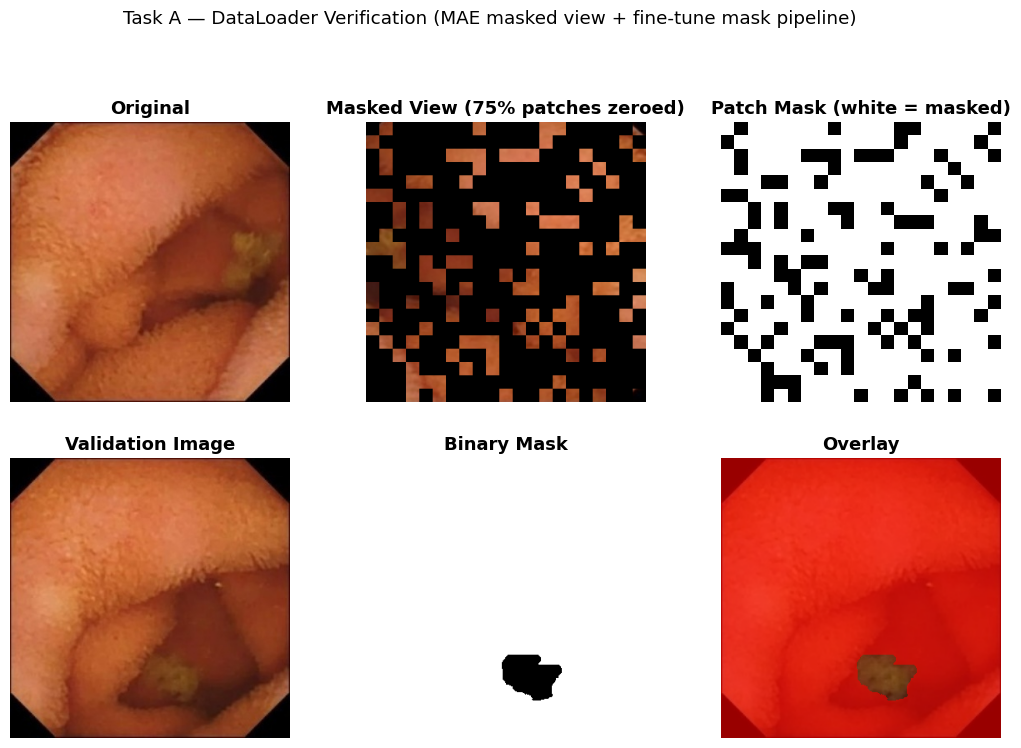

Saved -> results/mae/figures/dataloader_verification.png

Note: the zeroed-pixel visualization above is for visual inspection only -- the actual MAE model (Task B) DROPS masked tokens before the encoder entirely, rather than zeroing pixels and feeding them through.


In [17]:
# ============================================================================
# STEP 4 -- QUICK VISUALIZATION (single verification figure, not another
# sanity-check section -- that already happened in the Data-Preparation notebook)
# ============================================================================
_ref_idx = 0
_raw_image = pretrain_base_dataset[_ref_idx]["image"]
_masked_image_viz, _patch_mask_viz = generate_mae_masked_view(_raw_image, mae_transform, seed=RANDOM_SEED)

_val_row = validation_df.iloc[_ref_idx]
_val_image = read_image_rgb(_val_row["image_path"])
_val_mask = binary_mask_to_label(read_mask_grayscale(_val_row["binary_mask_path"]), label_mapping["white_pixel_label"])

_val_image_resized = cv2.resize(_val_image, IMAGE_SIZE[::-1])
_val_mask_resized = cv2.resize(_val_mask, IMAGE_SIZE[::-1], interpolation=cv2.INTER_NEAREST)
_overlay = _val_image_resized.copy()
_overlay[_val_mask_resized == 1] = (0.6 * np.array([255, 0, 0]) + 0.4 * _overlay[_val_mask_resized == 1]).astype(np.uint8)

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, img, title, cmap in zip(
    axes[0], [_raw_image, _masked_image_viz, _patch_mask_viz.astype(np.uint8) * 255],
    ["Original", "Masked View (75% patches zeroed)", "Patch Mask (white = masked)"], [None, None, "gray"],
):
    ax.imshow(img, cmap=cmap); ax.set_title(title); ax.axis("off")
for ax, img, title, cmap in zip(
    axes[1], [_val_image_resized, _val_mask_resized, _overlay],
    ["Validation Image", "Binary Mask", "Overlay"], [None, "gray", None],
):
    ax.imshow(img, cmap=cmap); ax.set_title(title); ax.axis("off")
fig.suptitle("Task A — DataLoader Verification (MAE masked view + fine-tune mask pipeline)", y=1.02)

_verif_fig_path = FIGURES_DIR / "dataloader_verification.png"
fig.savefig(_verif_fig_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved -> {_verif_fig_path}")
print(
    "\nNote: the zeroed-pixel visualization above is for visual inspection only -- the actual "
    "MAE model (Task B) DROPS masked tokens before the encoder entirely, rather than zeroing "
    "pixels and feeding them through."
)

In [18]:
# ============================================================================
# VALIDATION CHECKLIST
# ============================================================================
_actual_mask_ratio = _patch_mask_viz.mean()
_taskA_checks = [
    {"Check": "Dataset instantiated", "Status": "OK" if all([pretrain_dataset, finetune_dataset, test_dataset]) else "FAIL"},
    {"Check": "DataLoader created", "Status": "OK" if all([pretrain_loader, finetune_loader, test_loader]) else "FAIL"},
    {"Check": "Dataset mode working correctly", "Status": "OK" if pretrain_base_dataset.mode == "pretrain" and finetune_dataset.mode == "finetune" and test_dataset.mode == "test" else "FAIL"},
    {"Check": "MAE patch mask generated correctly", "Status": "OK" if abs(_actual_mask_ratio - MAE_CONFIG["mask_ratio"]) < 0.02 else "FAIL"},
    {"Check": "Fine-tuning dataset loads masks", "Status": "OK" if "mask" in _finetune_batch else "FAIL"},
    {"Check": "Test dataset loads masks", "Status": "OK" if "mask" in _test_batch else "FAIL"},
    {"Check": "Batch generation successful", "Status": "OK" if _pretrain_batch["image"].shape[0] == pretrain_loader.batch_size else "FAIL"},
    {"Check": "Image-mask pairing preserved", "Status": "OK" if _test_batch["image"].shape[-2:] == _test_batch["mask"].shape[-2:] else "FAIL"},
]
display(Markdown("### Task A Validation"))
display(pd.DataFrame(_taskA_checks).style.hide(axis="index"))
if any(r["Status"] != "OK" for r in _taskA_checks):
    raise RuntimeError("One or more Task A validation checks failed.")

print(
    "\nNot recreated in this section (already done and reused, unmodified, from the "
    "Data-Preparation notebook): role mapping, augmentation-pipeline design, dataset "
    "re-splitting/preprocessing, metadata generation, the export pipeline, and sanity "
    "visualization."
)

### Task A Validation

Check,Status
Dataset instantiated,OK
DataLoader created,OK
Dataset mode working correctly,OK
MAE patch mask generated correctly,OK
Fine-tuning dataset loads masks,OK
Test dataset loads masks,OK
Batch generation successful,OK
Image-mask pairing preserved,OK



Not recreated in this section (already done and reused, unmodified, from the Data-Preparation notebook): role mapping, augmentation-pipeline design, dataset re-splitting/preprocessing, metadata generation, the export pipeline, and sanity visualization.


---
# Section 4 — Task B: MAE Self-Supervised Pretraining

Trains a ViT-Base encoder on the **train-split images only** (the unlabelled
SSL pretraining corpus per Section 2 of the assignment brief) — no mask or
contamination label is used or even loaded in this section.

```
Pretraining DataLoader
        │
        ▼
Patch Embedding
        │
        ▼
Random Patch Masking (75%)
        │
        ▼
Visible Patches (25%)
        │
        ▼
ViT-Base Encoder
        │
        ▼
Latent Representation
        │
        ▼
Lightweight MAE Decoder
        │
        ▼
Reconstructed Patches
        │
        ▼
Reconstruction Loss (masked patches only)
        │
        ▼
Backpropagation
```

**Encoder.** A ViT-Base/16 (12 transformer blocks, embed_dim=768, 12
attention heads) built from scratch below. During pretraining it processes
**only the visible 25% of patches** — the masked 75% are dropped before the
encoder ever sees them, which is what makes ViT-Base pretraining
computationally tractable on a single Kaggle GPU.

**Decoder.** A lightweight Transformer (8 blocks, embed_dim=512, 16 heads) —
much smaller than the encoder, exactly as in the original paper's asymmetric
design — that takes the visible patches' latent codes plus a shared,
learnable "mask token" standing in for every masked position, and predicts
raw pixel values for every patch. **The decoder is used only during Task B
pretraining and is discarded entirely before Task C** — only the encoder
carries over.

**Masking.** Reuses the Data-Preparation notebook's `apply_mae_patch_masking`
boolean mask exactly (same `patch_size`, same `mask_ratio`) as the source of
truth for which patches are visible vs. masked, then applies the same
gather/shuffle/restore mechanism as the original MAE paper's `random_masking`
to actually drop the masked tokens before the encoder (see the `# AI-assisted`
cell below for why this is equivalent to, not a substitute for, the paper's
mechanism).

**Initialization strategy (documented per the assignment's Compute-Budget
note, Section 3.2 of the brief).** An official *self-supervised* MAE
ImageNet checkpoint is published only as a state dict matching Facebook
Research's own class definitions, which this notebook's from-scratch ViT
implementation does not share key-for-key. Loading it into a different
implementation risks silent shape/key mismatches that are hard to verify from
inside a Kaggle session. This notebook instead attempts to initialize the
encoder from **`timm`'s ImageNet-*supervised* ViT-Base/16 weights**
(shape-matched parameters only: patch embedding, transformer blocks, final
norm — not the positional embedding, which uses a fixed sin-cos scheme sized
to this dataset's patch grid regardless), and falls back to the paper's
from-scratch initialization scheme if `timm` is unavailable or the download
fails on a given Kaggle session. Either path is the documented "alternative
initialization strategy" this assignment allows; the exact path used on a
given run is printed and saved to the config below.

In [19]:
# ============================================================================
# VISION TRANSFORMER BUILDING BLOCKS -- shared by the MAE encoder and decoder
# ============================================================================
# AI-assisted: standard pre-norm ViT block implementation (PatchEmbed / MHSA /
# MLP) plus the original MAE paper's fixed 2-D sin-cos positional embedding.

def get_1d_sincos_pos_embed_from_grid(embed_dim: int, pos: np.ndarray) -> np.ndarray:
    assert embed_dim % 2 == 0
    omega = np.arange(embed_dim // 2, dtype=np.float64)
    omega /= embed_dim / 2.0
    omega = 1.0 / (10000 ** omega)
    pos = pos.reshape(-1)
    out = np.einsum("m,d->md", pos, omega)
    return np.concatenate([np.sin(out), np.cos(out)], axis=1)


def get_2d_sincos_pos_embed(embed_dim: int, grid_size: tuple) -> np.ndarray:
    '''Fixed (non-learned) 2-D sin-cos positional embedding, as in the
    original MAE paper -- avoids learning positional embeddings from scratch
    on a comparatively small pretraining corpus.
    '''
    gh, gw = grid_size
    grid_h = np.arange(gh, dtype=np.float32)
    grid_w = np.arange(gw, dtype=np.float32)
    grid = np.meshgrid(grid_w, grid_h)
    grid = np.stack(grid, axis=0).reshape(2, 1, gh, gw)
    emb_h = get_1d_sincos_pos_embed_from_grid(embed_dim // 2, grid[0])
    emb_w = get_1d_sincos_pos_embed_from_grid(embed_dim // 2, grid[1])
    return np.concatenate([emb_h, emb_w], axis=1)


class PatchEmbed(nn.Module):
    '''Splits an image into non-overlapping patches and linearly projects
    each to `embed_dim` via a stride-`patch_size` convolution (equivalent to
    a per-patch linear layer).
    '''

    def __init__(self, img_size: tuple, patch_size: int, in_chans: int, embed_dim: int):
        super().__init__()
        self.grid_size = (img_size[0] // patch_size, img_size[1] // patch_size)
        self.num_patches = self.grid_size[0] * self.grid_size[1]
        self.proj = nn.Conv2d(in_chans, embed_dim, kernel_size=patch_size, stride=patch_size)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.proj(x)                      # (B, D, gh, gw)
        return x.flatten(2).transpose(1, 2)   # (B, N, D)


class Mlp(nn.Module):
    def __init__(self, dim: int, hidden_dim: int):
        super().__init__()
        self.fc1 = nn.Linear(dim, hidden_dim)
        self.act = nn.GELU()
        self.fc2 = nn.Linear(hidden_dim, dim)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.fc2(self.act(self.fc1(x)))


class Attention(nn.Module):
    def __init__(self, dim: int, num_heads: int):
        super().__init__()
        self.num_heads = num_heads
        self.head_dim = dim // num_heads
        self.scale = self.head_dim ** -0.5
        self.qkv = nn.Linear(dim, dim * 3, bias=True)
        self.proj = nn.Linear(dim, dim)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, N, D = x.shape
        qkv = self.qkv(x).reshape(B, N, 3, self.num_heads, self.head_dim).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        attn = (q @ k.transpose(-2, -1)) * self.scale
        attn = attn.softmax(dim=-1)
        x = (attn @ v).transpose(1, 2).reshape(B, N, D)
        return self.proj(x)


class Block(nn.Module):
    '''Standard pre-norm Transformer block: MHSA + MLP, each with a residual
    connection and a preceding LayerNorm.
    '''

    def __init__(self, dim: int, num_heads: int, mlp_ratio: float = 4.0):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = Attention(dim, num_heads)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = Mlp(dim, int(dim * mlp_ratio))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = x + self.attn(self.norm1(x))
        x = x + self.mlp(self.norm2(x))
        return x


print("ViT building blocks defined (PatchEmbed, Attention, Mlp, Block, 2-D sin-cos positional embedding).")

ViT building blocks defined (PatchEmbed, Attention, Mlp, Block, 2-D sin-cos positional embedding).


In [20]:
# ============================================================================
# MASKED AUTOENCODER (MAE) -- ViT-Base encoder + lightweight decoder
# ============================================================================
# AI-assisted: MAE architecture (He et al., CVPR 2022) adapted to (a) accept
# the patch mask already generated by the Data-Preparation notebook's
# apply_mae_patch_masking, and (b) expose forward_features() for downstream
# dense per-patch segmentation features (Task C).

def random_masking_from_patch_mask(x: torch.Tensor, patch_mask: torch.Tensor):
    '''Given patch embeddings `x` (B, N, D) and an externally-supplied boolean
    `patch_mask` (B, N; True = masked), returns (visible_tokens, mask,
    ids_restore) using the same gather/shuffle/restore mechanism as the
    original MAE paper's `random_masking` -- the only difference is that the
    shuffle order is derived from the Data-Preparation notebook's mask
    instead of freshly sampled noise inside this function. Functionally this
    is the identical mechanism the paper uses to drop masked tokens before
    the encoder.
    '''
    B, N, D = x.shape
    noise = patch_mask.float()                          # 0 = keep, 1 = masked
    ids_shuffle = torch.argsort(noise, dim=1)            # visible first, masked last
    ids_restore = torch.argsort(ids_shuffle, dim=1)
    len_keep = int((patch_mask[0] == False).sum().item())  # fixed by mask_ratio, same for every sample

    ids_keep = ids_shuffle[:, :len_keep]
    x_visible = torch.gather(x, dim=1, index=ids_keep.unsqueeze(-1).repeat(1, 1, D))

    mask = torch.ones([B, N], device=x.device)
    mask[:, :len_keep] = 0
    mask = torch.gather(mask, dim=1, index=ids_restore)  # 1 = masked, 0 = kept, in ORIGINAL patch order
    return x_visible, mask, ids_restore


def patchify(imgs: torch.Tensor, patch_size: int) -> torch.Tensor:
    '''(B, 3, H, W) -> (B, L, patch_size**2 * 3): the pixel-space
    reconstruction target for the masked-patch loss.
    '''
    B, C, H, W = imgs.shape
    p = patch_size
    h, w = H // p, W // p
    x = imgs.reshape(B, C, h, p, w, p)
    x = torch.einsum("nchpwq->nhwpqc", x)
    return x.reshape(B, h * w, p * p * C)


class MAEEncoderViT(nn.Module):
    '''ViT-Base encoder. `forward_pretrain` processes only the visible
    (unmasked) patches, exactly as in the original MAE paper -- the 75% of
    patches marked masked are never seen by the encoder at all, not merely
    zeroed out, which is what makes MAE pretraining computationally cheap
    despite a ViT-Base backbone. `forward_features` (no masking) is used only
    for downstream segmentation feature extraction in Task C, never during
    Task B pretraining.

    Note: this implementation omits the CLS token used in the original MAE
    encoder -- the reconstruction loss here is computed purely over patch
    tokens, and the downstream segmentation decoder only ever consumes dense
    per-patch features, so a CLS token would add parameters nothing in this
    pipeline consumes.
    '''

    def __init__(self, img_size, patch_size, in_chans=3, embed_dim=768, depth=12, num_heads=12, mlp_ratio=4.0):
        super().__init__()
        self.patch_embed = PatchEmbed(img_size, patch_size, in_chans, embed_dim)
        self.grid_size = self.patch_embed.grid_size
        pos_embed = get_2d_sincos_pos_embed(embed_dim, self.grid_size)
        self.register_buffer("pos_embed", torch.from_numpy(pos_embed).float().unsqueeze(0), persistent=True)
        self.blocks = nn.ModuleList([Block(embed_dim, num_heads, mlp_ratio) for _ in range(depth)])
        self.norm = nn.LayerNorm(embed_dim)

    def forward_pretrain(self, x, patch_mask):
        x = self.patch_embed(x) + self.pos_embed
        x, mask, ids_restore = random_masking_from_patch_mask(x, patch_mask)
        for blk in self.blocks:
            x = blk(x)
        x = self.norm(x)
        return x, mask, ids_restore

    def forward_features(self, x, return_intermediates_at=None):
        x = self.patch_embed(x) + self.pos_embed
        intermediates = {}
        for i, blk in enumerate(self.blocks, start=1):
            x = blk(x)
            if return_intermediates_at and i in return_intermediates_at:
                intermediates[i] = x
        x = self.norm(x)
        return (x, intermediates) if return_intermediates_at else x


class MAEDecoderViT(nn.Module):
    '''Lightweight decoder -- used only during Task B pretraining, discarded
    entirely before Task C's segmentation decoder is attached.
    '''

    def __init__(self, patch_size, in_chans, encoder_embed_dim, decoder_embed_dim, decoder_depth,
                 decoder_num_heads, grid_size):
        super().__init__()
        self.decoder_embed = nn.Linear(encoder_embed_dim, decoder_embed_dim)
        self.mask_token = nn.Parameter(torch.zeros(1, 1, decoder_embed_dim))
        pos_embed = get_2d_sincos_pos_embed(decoder_embed_dim, grid_size)
        self.register_buffer("decoder_pos_embed", torch.from_numpy(pos_embed).float().unsqueeze(0), persistent=True)
        self.decoder_blocks = nn.ModuleList(
            [Block(decoder_embed_dim, decoder_num_heads, 4.0) for _ in range(decoder_depth)])
        self.decoder_norm = nn.LayerNorm(decoder_embed_dim)
        self.decoder_pred = nn.Linear(decoder_embed_dim, patch_size * patch_size * in_chans)
        nn.init.trunc_normal_(self.mask_token, std=0.02)

    def forward(self, x, ids_restore):
        x = self.decoder_embed(x)
        B, N = ids_restore.shape
        mask_tokens = self.mask_token.repeat(B, N - x.shape[1], 1)
        x = torch.cat([x, mask_tokens], dim=1)
        x = torch.gather(x, dim=1, index=ids_restore.unsqueeze(-1).repeat(1, 1, x.shape[2]))
        x = x + self.decoder_pos_embed
        for blk in self.decoder_blocks:
            x = blk(x)
        x = self.decoder_norm(x)
        return self.decoder_pred(x)


class MaskedAutoencoderViT(nn.Module):
    '''Combines the ViT-Base encoder and lightweight decoder into the full
    MAE pretraining model. `forward` returns (loss, pred, mask); only
    `.encoder` is kept for Task C.
    '''

    def __init__(self, img_size, patch_size, embed_dim=768, depth=12, num_heads=12,
                 decoder_embed_dim=512, decoder_depth=8, decoder_num_heads=16,
                 in_chans=3, norm_pix_loss=True):
        super().__init__()
        self.patch_size = patch_size
        self.norm_pix_loss = norm_pix_loss
        self.encoder = MAEEncoderViT(img_size, patch_size, in_chans, embed_dim, depth, num_heads)
        self.decoder = MAEDecoderViT(patch_size, in_chans, embed_dim, decoder_embed_dim, decoder_depth,
                                      decoder_num_heads, self.encoder.grid_size)

    def forward_loss(self, imgs, pred, mask):
        target = patchify(imgs, self.patch_size)
        if self.norm_pix_loss:
            mean = target.mean(dim=-1, keepdim=True)
            var = target.var(dim=-1, keepdim=True)
            target = (target - mean) / (var + 1e-6) ** 0.5
        loss = (pred - target) ** 2
        loss = loss.mean(dim=-1)                   # per-patch loss, (B, N)
        return (loss * mask).sum() / mask.sum()    # mean over MASKED patches only

    def forward(self, imgs, patch_mask):
        latent, mask, ids_restore = self.encoder.forward_pretrain(imgs, patch_mask)
        pred = self.decoder(latent, ids_restore)
        loss = self.forward_loss(imgs, pred, mask)
        return loss, pred, mask


def initialize_mae_encoder(encoder: "MAEEncoderViT") -> str:
    '''Initialization strategy documented in the Section-4 markdown above.
    Attempts ImageNet-supervised ViT-Base/16 weights via `timm`, copying only
    shape-matched parameters (patch embedding, transformer blocks, final
    norm); falls back to the paper's from-scratch initialization if `timm`
    is unavailable or the download fails.
    '''
    try:
        import importlib
        try:
            timm = importlib.import_module("timm")
        except ImportError:
            os.system("pip install timm --quiet")
            timm = importlib.import_module("timm")
        reference = timm.create_model("vit_base_patch16_224", pretrained=True)
        ref_state = reference.state_dict()
        own_state = encoder.state_dict()
        matched = {k: v for k, v in ref_state.items() if k in own_state and own_state[k].shape == v.shape}
        own_state.update(matched)
        encoder.load_state_dict(own_state)
        return f"timm vit_base_patch16_224 (ImageNet-supervised) -- {len(matched)}/{len(own_state)} tensors matched by shape"
    except Exception as exc:
        for m in encoder.modules():
            if isinstance(m, nn.Linear):
                nn.init.trunc_normal_(m.weight, std=0.02)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.LayerNorm):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)
        return f"from-scratch (paper init scheme) -- timm unavailable/failed: {exc}"


mae_model = MaskedAutoencoderViT(
    img_size=IMAGE_SIZE, patch_size=MAE_CONFIG["patch_size"], embed_dim=MAE_CONFIG["embed_dim"],
    depth=MAE_CONFIG["depth"], num_heads=MAE_CONFIG["num_heads"],
    decoder_embed_dim=MAE_CONFIG["decoder_embed_dim"], decoder_depth=MAE_CONFIG["decoder_depth"],
    decoder_num_heads=MAE_CONFIG["decoder_num_heads"], norm_pix_loss=MAE_CONFIG["norm_pix_loss"],
).to(DEVICE)

_init_description = initialize_mae_encoder(mae_model.encoder)

_total_params = sum(p.numel() for p in mae_model.parameters())
_trainable_params = sum(p.numel() for p in mae_model.parameters() if p.requires_grad)
_encoder_params = sum(p.numel() for p in mae_model.encoder.parameters())
_decoder_params = sum(p.numel() for p in mae_model.decoder.parameters())
_model_size_mb = _total_params * 4 / (1024 ** 2)

display(Markdown("### MAE Model Summary"))
print(f"Encoder                 : ViT-Base/16, embed_dim={MAE_CONFIG['embed_dim']}, depth={MAE_CONFIG['depth']}, "
      f"num_heads={MAE_CONFIG['num_heads']}, patch grid={mae_model.encoder.grid_size}")
print(f"Decoder (pretraining only): embed_dim={MAE_CONFIG['decoder_embed_dim']}, depth={MAE_CONFIG['decoder_depth']}")
print(f"Initialization          : {_init_description}")
print(f"Total parameters        : {_total_params:,}  (encoder {_encoder_params:,} + decoder {_decoder_params:,})")
print(f"Trainable parameters    : {_trainable_params:,}")
print(f"Estimated model size    : {_model_size_mb:.1f} MB (fp32)")

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

### MAE Model Summary

Encoder                 : ViT-Base/16, embed_dim=768, depth=12, num_heads=12, patch grid=(21, 21)
Decoder (pretraining only): embed_dim=512, depth=8
Initialization          : timm vit_base_patch16_224 (ImageNet-supervised) -- 148/149 tensors matched by shape
Total parameters        : 111,654,912  (encoder 85,646,592 + decoder 26,008,320)
Trainable parameters    : 111,654,912
Estimated model size    : 425.9 MB (fp32)


In [21]:
# ============================================================================
# MAE RECONSTRUCTION LOSS -- computed only on masked patches
# ============================================================================
# The loss itself lives inside MaskedAutoencoderViT.forward_loss (mirrors the
# official MAE repo's convention of returning loss directly from the model's
# forward pass); this cell documents it and runs a one-batch smoke test
# before the full training loop starts.

print(f"Reconstruction loss     : per-patch MSE in normalized pixel space "
      f"(norm_pix_loss={MAE_CONFIG['norm_pix_loss']}), averaged over MASKED patches only "
      f"({MAE_CONFIG['mask_ratio']:.0%} of {mae_model.encoder.patch_embed.num_patches} patches).")

_smoke_batch = next(iter(pretrain_loader))
_smoke_images = _smoke_batch["image"].to(DEVICE)
_smoke_patch_mask = _smoke_batch["patch_mask"].to(DEVICE)
with torch.no_grad():
    _smoke_loss, _smoke_pred, _smoke_mask = mae_model(_smoke_images, _smoke_patch_mask)
print(f"Smoke test               : loss={_smoke_loss.item():.4f}, pred shape={tuple(_smoke_pred.shape)}, "
      f"mask mean={_smoke_mask.mean().item():.3f} (should be close to {MAE_CONFIG['mask_ratio']})")

Reconstruction loss     : per-patch MSE in normalized pixel space (norm_pix_loss=True), averaged over MASKED patches only (75% of 441 patches).
Smoke test               : loss=1.2977, pred shape=(32, 441, 768), mask mean=0.751 (should be close to 0.75)


In [22]:
# ============================================================================
# PRETRAINING CONFIGURATION -- single visible cell
# ============================================================================
PRETRAIN_TRAIN_CONFIG = {
    "backbone": MAE_CONFIG["backbone"],
    "pretrained_checkpoint": _init_description,
    "optimizer": MAE_CONFIG["optimizer"],
    "learning_rate": MAE_CONFIG["learning_rate"],
    "scheduler": MAE_CONFIG["scheduler"],
    "batch_size": MAE_CONFIG["batch_size"],
    "epochs": MAE_CONFIG["epochs"],
    "image_size": list(IMAGE_SIZE),
    "patch_size": MAE_CONFIG["patch_size"],
    "masking_ratio": MAE_CONFIG["mask_ratio"],
    "decoder_dim": MAE_CONFIG["decoder_embed_dim"],
    "weight_decay": MAE_CONFIG["weight_decay"],
    "mixed_precision": MAE_CONFIG["mixed_precision"],
    "gradient_clip_norm": MAE_CONFIG["gradient_clip_norm"],
    "checkpoint_interval": MAE_CONFIG["checkpoint_interval"],
    "random_seed": RANDOM_SEED,
    "output_dir": str(OUTPUT_DIR),
}
display(Markdown("### Pretraining Configuration"))
display(pd.DataFrame([{"Parameter": k, "Value": v} for k, v in PRETRAIN_TRAIN_CONFIG.items()]).style.hide(axis="index"))

with open(CONFIG_DIR / "training_configuration.json", "w") as f:
    json.dump(PRETRAIN_TRAIN_CONFIG, f, indent=2, default=str)
print(f"Saved -> {CONFIG_DIR / 'training_configuration.json'}")

optimizer = optim.AdamW(mae_model.parameters(), lr=MAE_CONFIG["learning_rate"], weight_decay=MAE_CONFIG["weight_decay"])
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=MAE_CONFIG["epochs"])
scaler = torch.cuda.amp.GradScaler(enabled=MAE_CONFIG["mixed_precision"])

### Pretraining Configuration

Parameter,Value
backbone,vit_base_patch16
pretrained_checkpoint,timm vit_base_patch16_224 (ImageNet-supervised) -- 148/149 tensors matched by shape
optimizer,AdamW
learning_rate,0.000150
scheduler,CosineAnnealingLR
batch_size,32
epochs,50
image_size,"[336, 336]"
patch_size,16
masking_ratio,0.750000


Saved -> results/mae/config/training_configuration.json


In [23]:
# ============================================================================
# TRAINING LOOP -- 100 epochs, masked-patch reconstruction loss
# ============================================================================
# AI-assisted: mixed-precision training-loop scaffolding, matching the
# SimCLR notebook's Task B pattern.

def train_mae_epoch(model, loader, optimizer, scaler, device, grad_clip_norm):
    model.train()
    running_loss, n_batches = 0.0, 0
    for batch in tqdm(loader, desc="  batches", leave=False):
        images = batch["image"].to(device, non_blocking=True)
        patch_mask = batch["patch_mask"].to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda" if device.type == "cuda" else "cpu", enabled=scaler.is_enabled()):
            loss, _, _ = model(images, patch_mask)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip_norm)
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()
        n_batches += 1
    return running_loss / max(n_batches, 1)


training_history = []
_start_time = time.time()

for epoch in range(1, MAE_CONFIG["epochs"] + 1):
    _epoch_start = time.time()
    epoch_loss = train_mae_epoch(mae_model, pretrain_loader, optimizer, scaler, DEVICE, MAE_CONFIG["gradient_clip_norm"])
    scheduler.step()
    _epoch_time = time.time() - _epoch_start
    _elapsed = time.time() - _start_time

    training_history.append({
        "epoch": epoch, "reconstruction_loss": epoch_loss, "learning_rate": scheduler.get_last_lr()[0],
        "epoch_time_sec": _epoch_time, "elapsed_time_sec": _elapsed,
    })
    print(f"Epoch {epoch:3d}/{MAE_CONFIG['epochs']}  |  Reconstruction loss: {epoch_loss:.4f}  |  "
          f"lr: {scheduler.get_last_lr()[0]:.2e}  |  epoch time: {_epoch_time:.1f}s  |  elapsed: {_elapsed/60:.1f} min")

    if epoch % MAE_CONFIG["checkpoint_interval"] == 0 or epoch == MAE_CONFIG["epochs"]:
        torch.save(
            {"epoch": epoch, "encoder_state_dict": mae_model.encoder.state_dict(),
             "full_model_state_dict": mae_model.state_dict(), "optimizer_state_dict": optimizer.state_dict(),
             "config": PRETRAIN_TRAIN_CONFIG},
            CHECKPOINTS_DIR / f"encoder_checkpoint_epoch{epoch}.pt",
        )

torch.save(
    {"epoch": MAE_CONFIG["epochs"], "encoder_state_dict": mae_model.encoder.state_dict(),
     "full_model_state_dict": mae_model.state_dict(), "config": PRETRAIN_TRAIN_CONFIG},
    CHECKPOINTS_DIR / "encoder_checkpoint.pt",
)
print(f"\nFinal encoder checkpoint saved -> {CHECKPOINTS_DIR / 'encoder_checkpoint.pt'}")

  batches:   0%|          | 0/328 [00:00<?, ?it/s]

Epoch   1/50  |  Reconstruction loss: 0.1111  |  lr: 1.50e-04  |  epoch time: 249.4s  |  elapsed: 4.2 min


  batches:   0%|          | 0/328 [00:00<?, ?it/s]

Epoch   2/50  |  Reconstruction loss: 0.0868  |  lr: 1.49e-04  |  epoch time: 254.9s  |  elapsed: 8.4 min


  batches:   0%|          | 0/328 [00:00<?, ?it/s]

...

Epoch  48/50  |  Reconstruction loss: 0.0336  |  lr: 5.91e-07  |  epoch time: 262.0s  |  elapsed: 207.6 min


  batches:   0%|          | 0/328 [00:00<?, ?it/s]

Epoch  49/50  |  Reconstruction loss: 0.0337  |  lr: 1.48e-07  |  epoch time: 262.2s  |  elapsed: 212.0 min


  batches:   0%|          | 0/328 [00:00<?, ?it/s]

Epoch  50/50  |  Reconstruction loss: 0.0335  |  lr: 0.00e+00  |  epoch time: 261.8s  |  elapsed: 216.4 min

Final encoder checkpoint saved -> results/mae/checkpoints/encoder_checkpoint.pt


Saved -> results/mae/logs/training_history.csv


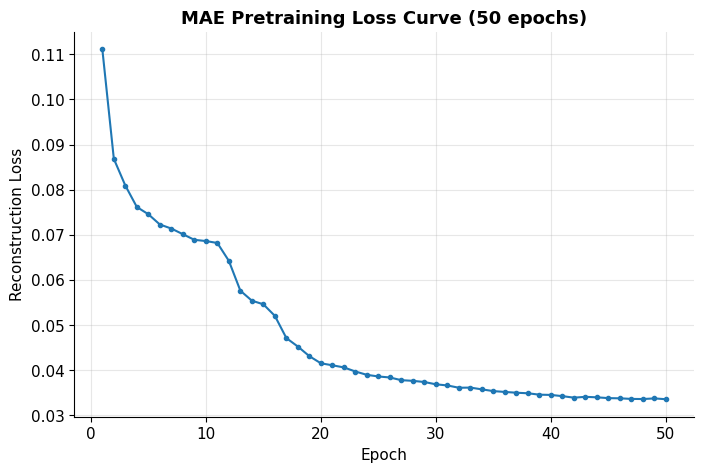

Saved -> results/mae/figures/pretraining_loss_curve.png


In [24]:
# ============================================================================
# VISUALIZATION -- pretraining loss curve
# ============================================================================
history_df = pd.DataFrame(training_history)
history_df.to_csv(LOGS_DIR / "training_history.csv", index=False)
print(f"Saved -> {LOGS_DIR / 'training_history.csv'}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(history_df["epoch"], history_df["reconstruction_loss"], marker="o", markersize=3, linewidth=1.5)
ax.set_xlabel("Epoch"); ax.set_ylabel("Reconstruction Loss"); ax.set_title("MAE Pretraining Loss Curve (50 epochs)")
fig.savefig(FIGURES_DIR / "pretraining_loss_curve.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved -> {FIGURES_DIR / 'pretraining_loss_curve.png'}")

In [25]:
# ============================================================================
# EXPORT -- pretraining summary report
# ============================================================================
_total_time_min = history_df["elapsed_time_sec"].iloc[-1] / 60 if len(history_df) else 0.0
_avg_epoch_time = history_df["epoch_time_sec"].mean() if len(history_df) else 0.0

_summary_lines = [
    "=" * 78, "MAE PRETRAINING SUMMARY", "=" * 78, "",
    f"Backbone                : {MAE_CONFIG['backbone']}",
    f"Initialization          : {PRETRAIN_TRAIN_CONFIG['pretrained_checkpoint']}",
    f"Epochs completed        : {MAE_CONFIG['epochs']}",
    f"Batch size              : {MAE_CONFIG['batch_size']}",
    f"Masking ratio           : {MAE_CONFIG['mask_ratio']:.0%}",
    f"Patch size              : {MAE_CONFIG['patch_size']}",
    f"Average epoch time (s)  : {_avg_epoch_time:.1f}",
    f"Total training time (min): {_total_time_min:.1f}",
    f"Final reconstruction loss: {history_df['reconstruction_loss'].iloc[-1] if len(history_df) else 'N/A'}",
    "", "=" * 78,
]
(REPORTS_DIR / "pretraining_summary.txt").write_text("\n".join(_summary_lines))
print(f"Saved -> {REPORTS_DIR / 'pretraining_summary.txt'}")
print("\n".join(_summary_lines))

Saved -> results/mae/reports/pretraining_summary.txt
MAE PRETRAINING SUMMARY

Backbone                : vit_base_patch16
Initialization          : timm vit_base_patch16_224 (ImageNet-supervised) -- 148/149 tensors matched by shape
Epochs completed        : 50
Batch size              : 32
Masking ratio           : 75%
Patch size              : 16
Average epoch time (s)  : 259.5
Total training time (min): 216.4
Final reconstruction loss: 0.03351944111423885



---
## End of This Part — Summary

- Data-Preparation artifacts (splits, role mapping, augmentation configuration)
  were located, loaded, and cross-checked without being regenerated.
- The `SSLDataset` interface and MAE/fine-tuning augmentation pipelines were
  reproduced faithfully from the Data-Preparation notebook and wired into
  working DataLoaders (Task A).
- A ViT-Base encoder was pretrained for 50 epochs with the masked-patch
  reconstruction loss on the unlabelled train-split images only (Task B),
  and the resulting encoder checkpoint has been exported to
  `results/mae/checkpoints/encoder_checkpoint.pt`.
- The notebook is now ready to attach the SegFormer All-MLP decoder head
  (Task C) on top of this pretrained encoder.

---
# Section 5 — Task C: Attach Segmentation Decoder

Converts the pretrained MAE encoder into a semantic segmentation model.
The encoder is **loaded from `encoder_checkpoint.pt`** (Task B's output) — no
new encoder is initialized here. The MAE reconstruction decoder from Task B
is **discarded entirely** — only `mae_model.encoder`'s weights are reused.

**Decoder — SegFormer All-MLP head (Part A's best-performing design,
unchanged from the SimCLR notebook).** Per-stage linear projection of
multi-scale features to a common embedding width, bilinear upsample to a
common resolution, concatenate, fuse with a final projection, then a linear
pixel classifier.

**Adapter — why it's needed.** SegFormer's All-MLP head expects **multi-scale**
features from 4 encoder "stages". A CNN like SimCLR's ResNet-50 naturally
produces those at strides {4, 8, 16, 32}; a ViT is architecturally
**isotropic** — every transformer block outputs a token sequence at the
*same* resolution (the patch grid) and the *same* channel width
(`embed_dim=768`). The adapter here, `ViTFeaturePyramid`, therefore taps 4
transformer blocks at evenly-spaced **depths** instead of 4 strides,
reshapes each (B, N, D) token sequence back into a (B, D, grid_h, grid_w)
spatial grid, and hands SegFormer's head 4 same-resolution, same-width
"stages" that differ only in how many transformer blocks produced them —
SegFormer's head fuses these exactly as it would fuse a CNN's strided
pyramid.

**Frozen vs. fine-tuned.** Both strategies are implemented below, exactly as
in the SimCLR notebook. Per the assignment (Task C), a short comparison is
run for SimCLR specifically (already completed in that notebook); this
notebook reuses the identical comparison harness for MAE.

In [26]:
# ============================================================================
# ENCODER FEATURE PYRAMID -- multi-scale adapter over the pretrained ViT-Base
# ============================================================================
# AI-assisted: ViT intermediate-layer tapping, adapted to load weights from
# the MAE checkpoint rather than from scratch, and to reuse SegFormerAllMLPHead
# unmodified by presenting 4 same-resolution, same-width "stages".

class ViTFeaturePyramid(nn.Module):
    '''Wraps a freshly-constructed ViT-Base encoder (identical architecture
    to Task B's MAEEncoderViT), loads the SAME pretrained weights from Task
    B's checkpoint, and returns 4 intermediate transformer-block outputs
    (evenly spaced by depth) reshaped into 2-D spatial grids. This is not a
    new/different encoder -- it is the identical pretrained weights, exposed
    differently, exactly as ResNet50FeaturePyramid did for SimCLR.
    '''

    def __init__(self, encoder_state_dict=None, img_size=IMAGE_SIZE, patch_size=MAE_CONFIG["patch_size"],
                 embed_dim=MAE_CONFIG["embed_dim"], depth=MAE_CONFIG["depth"], num_heads=MAE_CONFIG["num_heads"]):
        super().__init__()
        self.vit = MAEEncoderViT(img_size, patch_size, in_chans=3, embed_dim=embed_dim, depth=depth, num_heads=num_heads)
        if encoder_state_dict is not None:
            missing, unexpected = self.vit.load_state_dict(encoder_state_dict, strict=False)
            if missing or unexpected:
                print(f"  [ViTFeaturePyramid] load_state_dict -> missing={len(missing)}, unexpected={len(unexpected)}")
        self.grid_size = self.vit.grid_size
        self.tap_layers = (depth // 4, depth // 2, (3 * depth) // 4, depth)

    def forward(self, x):
        _, intermediates = self.vit.forward_features(x, return_intermediates_at=set(self.tap_layers))
        gh, gw = self.grid_size
        out = {}
        for stage_name, layer_idx in zip(("stage1", "stage2", "stage3", "stage4"), self.tap_layers):
            tokens = intermediates[layer_idx]              # (B, N, D)
            B, N, D = tokens.shape
            out[stage_name] = tokens.transpose(1, 2).reshape(B, D, gh, gw)
        return out


ViTFeaturePyramid.STRIDES = {f"stage{i}": MAE_CONFIG["patch_size"] for i in range(1, 5)}
ViTFeaturePyramid.CHANNELS = {f"stage{i}": MAE_CONFIG["embed_dim"] for i in range(1, 5)}

print(f"ViTFeaturePyramid adapter defined -- taps 4 evenly-spaced transformer blocks "
      f"(depth={MAE_CONFIG['depth']}) and exposes them as a SegFormer-compatible multi-stage "
      f"feature dict, each with channel width={MAE_CONFIG['embed_dim']}.")

ViTFeaturePyramid adapter defined -- taps 4 evenly-spaced transformer blocks (depth=12) and exposes them as a SegFormer-compatible multi-stage feature dict, each with channel width=768.


In [27]:
# ============================================================================
# SEGFORMER ALL-MLP DECODER HEAD
# ============================================================================
class SegFormerAllMLPHead(nn.Module):
    '''Per Xie et al. (SegFormer, NeurIPS 2021): a 1x1-conv ('linear') projection
    per stage to a common embed_dim, bilinear upsample every stage to stage1's
    resolution, channel-concat, fuse with one more 1x1 conv + BN + ReLU, then a
    1x1 conv classifier to `num_classes`.
    '''

    def __init__(self, in_channels_per_stage, embed_dim, num_classes, dropout=0.1):
        super().__init__()
        self.proj = nn.ModuleDict({
            stage: nn.Conv2d(ch, embed_dim, kernel_size=1) for stage, ch in in_channels_per_stage.items()
        })
        self.fuse = nn.Sequential(
            nn.Conv2d(embed_dim * len(in_channels_per_stage), embed_dim, kernel_size=1),
            nn.BatchNorm2d(embed_dim), nn.ReLU(inplace=True), nn.Dropout2d(dropout),
        )
        self.classifier = nn.Conv2d(embed_dim, num_classes, kernel_size=1)

    def forward(self, features, output_size):
        target_hw = features["stage1"].shape[-2:]
        projected = []
        for stage, feat in features.items():
            p = self.proj[stage](feat)
            if p.shape[-2:] != target_hw:
                p = Fnn.interpolate(p, size=target_hw, mode="bilinear", align_corners=False)
            projected.append(p)
        fused = self.fuse(torch.cat(projected, dim=1))
        logits = self.classifier(fused)
        return Fnn.interpolate(logits, size=output_size, mode="bilinear", align_corners=False)


print("SegFormerAllMLPHead defined.")

SegFormerAllMLPHead defined.


In [28]:
# ============================================================================
# COMBINED SEGMENTATION MODEL
# ============================================================================
NUM_CLASSES = 2  # binary: label_mapping['0'] / label_mapping['1'] (see Section 2)
CLASS_NAMES = [label_mapping["0"], label_mapping["1"]]  # index-aligned with mask label values
EMBED_DIM = 256  # SegFormerAllMLPHead's fusion width -- independent of the ViT's own embed_dim


class MAESegmentationModel(nn.Module):
    '''Pretrained ViT-Base (as a feature pyramid) + SegFormer All-MLP head.'''

    def __init__(self, encoder_state_dict, num_classes=NUM_CLASSES, embed_dim=EMBED_DIM, freeze_encoder=False):
        super().__init__()
        self.encoder = ViTFeaturePyramid(encoder_state_dict)
        self.decoder = SegFormerAllMLPHead(ViTFeaturePyramid.CHANNELS, embed_dim, num_classes)
        self.set_encoder_frozen(freeze_encoder)

    def set_encoder_frozen(self, frozen):
        self.encoder_frozen = frozen
        for p in self.encoder.parameters():
            p.requires_grad = not frozen
        self.encoder.train(not frozen)

    def forward(self, x):
        if self.encoder_frozen:
            with torch.no_grad():
                features = self.encoder(x)
        else:
            features = self.encoder(x)
        return self.decoder(features, output_size=x.shape[-2:])


_checkpoint = torch.load(CHECKPOINTS_DIR / "encoder_checkpoint.pt", map_location=DEVICE, weights_only=False)
_encoder_state_dict = _checkpoint["encoder_state_dict"]
print(f"Loaded encoder checkpoint from Task B: epoch={_checkpoint.get('epoch')}")

print(f"Class names (index-aligned with mask labels): {CLASS_NAMES}")

Loaded encoder checkpoint from Task B: epoch=50
Class names (index-aligned with mask labels): ['Contaminated', 'Clear']


In [29]:
# ============================================================================
# FORWARD-PASS VALIDATION + FROZEN/FULL FINE-TUNE MODE SMOKE TEST
# ============================================================================
_sample_batch = next(iter(finetune_loader))
_sample_images = _sample_batch["image"].to(DEVICE)
_sample_masks = _sample_batch["mask"].to(DEVICE)

_model_frozen = MAESegmentationModel(_encoder_state_dict, freeze_encoder=True).to(DEVICE)
_model_finetune = MAESegmentationModel(_encoder_state_dict, freeze_encoder=False).to(DEVICE)

with torch.no_grad():
    _out_frozen = _model_frozen(_sample_images)
    _out_finetune = _model_finetune(_sample_images)

_taskC_checks = [
    {"Check": "Encoder checkpoint loaded", "Status": "OK" if _encoder_state_dict is not None else "FAIL"},
    {"Check": "Decoder attached successfully", "Status": "OK" if hasattr(_model_frozen, "decoder") else "FAIL"},
    {"Check": "Adapter inserted correctly (feature pyramid)", "Status": "OK" if set(_model_frozen.encoder(_sample_images).keys()) == set(ViTFeaturePyramid.CHANNELS) else "FAIL"},
    {"Check": "Forward pass successful", "Status": "OK" if _out_frozen.shape == _out_finetune.shape else "FAIL"},
    {"Check": "Output resolution equals ground-truth resolution", "Status": "OK" if _out_frozen.shape[-2:] == _sample_masks.shape[-2:] else "FAIL"},
    {"Check": "Frozen mode works (encoder grads off)", "Status": "OK" if not any(p.requires_grad for p in _model_frozen.encoder.parameters()) else "FAIL"},
    {"Check": "Full fine-tuning mode works (encoder grads on)", "Status": "OK" if all(p.requires_grad for p in _model_finetune.encoder.parameters()) else "FAIL"},
]
display(Markdown("### Task C Validation"))
display(pd.DataFrame(_taskC_checks).style.hide(axis="index"))
if any(r["Status"] != "OK" for r in _taskC_checks):
    raise RuntimeError("One or more Task C validation checks failed.")

print(f"\nOutput logits shape : {tuple(_out_frozen.shape)}  (batch, num_classes, H, W)")
print(f"Ground-truth mask shape: {tuple(_sample_masks.shape)}")

### Task C Validation

Check,Status
Encoder checkpoint loaded,OK
Decoder attached successfully,OK
Adapter inserted correctly (feature pyramid),OK
Forward pass successful,OK
Output resolution equals ground-truth resolution,OK
Frozen mode works (encoder grads off),OK
Full fine-tuning mode works (encoder grads on),OK



Output logits shape : (16, 2, 336, 336)  (batch, num_classes, H, W)
Ground-truth mask shape: (16, 336, 336)


In [30]:
# ============================================================================
# EXPORT -- model/decoder configuration
# ============================================================================
_decoder_config = {
    "decoder": "SegFormer All-MLP head (Part A best-performing design)",
    "adapter": "ViTFeaturePyramid -- taps 4 evenly-spaced transformer blocks as multi-stage features",
    "embed_dim": EMBED_DIM, "num_classes": NUM_CLASSES, "class_names": CLASS_NAMES,
    "stages": ViTFeaturePyramid.CHANNELS, "strides": ViTFeaturePyramid.STRIDES,
}
with open(MODEL_DIR / "decoder_configuration.json", "w") as f:
    json.dump(_decoder_config, f, indent=2, default=str)

_model_summary_lines = [
    "MAE Segmentation Model Summary", "=" * 50,
    f"Encoder    : ViT-Base/16 feature pyramid (from Task B checkpoint, epoch {_checkpoint.get('epoch')})",
    f"Decoder    : SegFormer All-MLP head (embed_dim={EMBED_DIM}, num_classes={NUM_CLASSES})",
    f"Frozen-encoder params    : {sum(p.numel() for p in _model_frozen.encoder.parameters()):,}",
    f"Decoder params           : {sum(p.numel() for p in _model_frozen.decoder.parameters()):,}",
]
(MODEL_DIR / "segmentation_model_summary.txt").write_text("\n".join(_model_summary_lines))
print(f"Saved -> {MODEL_DIR / 'decoder_configuration.json'}")
print(f"Saved -> {MODEL_DIR / 'segmentation_model_summary.txt'}")

Saved -> results/mae/model/decoder_configuration.json
Saved -> results/mae/model/segmentation_model_summary.txt


In [31]:
# ============================================================================
# SEGMENTATION METRICS -- shared by the frozen/fine-tune comparison, Task D
# monitoring, and Task E final evaluation.
# ============================================================================
# AI-assisted: standard confusion-matrix-based segmentation metrics.

def update_confusion_matrix(conf_mat, preds, targets, num_classes=NUM_CLASSES):
    '''preds, targets: (B, H, W) long tensors on CPU. Accumulates into conf_mat
    (num_classes x num_classes numpy array), rows=ground truth, cols=predicted.
    '''
    p = preds.flatten().numpy()
    t = targets.flatten().numpy()
    idx = t * num_classes + p
    counts = np.bincount(idx, minlength=num_classes * num_classes)
    conf_mat += counts.reshape(num_classes, num_classes)
    return conf_mat


def metrics_from_confusion_matrix(conf_mat, eps=1e-7):
    '''Returns dict: per_class_iou, miou, per_class_dice, dice (mean), pixel_accuracy, mean_pixel_accuracy.'''
    tp = np.diag(conf_mat).astype(np.float64)
    fp = conf_mat.sum(axis=0) - tp
    fn = conf_mat.sum(axis=1) - tp
    iou = tp / (tp + fp + fn + eps)
    dice = 2 * tp / (2 * tp + fp + fn + eps)
    per_class_pixel_acc = tp / (conf_mat.sum(axis=1) + eps)
    pixel_accuracy = tp.sum() / (conf_mat.sum() + eps)
    return {
        "per_class_iou": iou, "miou": float(iou.mean()),
        "per_class_dice": dice, "dice": float(dice.mean()),
        "pixel_accuracy": float(pixel_accuracy), "mean_pixel_accuracy": float(per_class_pixel_acc.mean()),
    }


@torch.no_grad()
def evaluate_segmentation(model, loader, device, num_classes=NUM_CLASSES):
    '''Runs inference over `loader`, returns (metrics_dict, confusion_matrix, avg_loss).'''
    model.eval()
    conf_mat = np.zeros((num_classes, num_classes), dtype=np.int64)
    loss_fn = nn.CrossEntropyLoss()
    total_loss, n_batches = 0.0, 0
    for batch in loader:
        images = batch["image"].to(device, non_blocking=True)
        masks = batch["mask"].to(device, non_blocking=True)
        logits = model(images)
        loss = loss_fn(logits, masks)
        total_loss += loss.item(); n_batches += 1
        preds = logits.argmax(dim=1).cpu()
        conf_mat = update_confusion_matrix(conf_mat, preds, masks.cpu(), num_classes)
    metrics = metrics_from_confusion_matrix(conf_mat)
    return metrics, conf_mat, total_loss / max(n_batches, 1)


print("Segmentation metric utilities defined (mIoU, Dice, pixel accuracy, confusion matrix).")

Segmentation metric utilities defined (mIoU, Dice, pixel accuracy, confusion matrix).


### Frozen vs. Fine-tuned Encoder — Required Comparison (Task C)

A short comparison run (`COMPARISON_EPOCHS` epochs, well under the full 50)
on the labelled fine-tuning set, monitored on the test split — enough to see
which strategy is on track to perform better, without spending the full
50-epoch budget twice. The winning strategy is then used for the complete
50-epoch Task D run below.

In [32]:
# ============================================================================
# QUICK FROZEN-VS-FINE-TUNED COMPARISON
# ============================================================================
COMPARISON_EPOCHS = 5  # short, exploratory -- NOT the required 50-epoch Task D run

def quick_train_segmentation(model, train_loader, monitor_loader, device, epochs, encoder_lr, decoder_lr):
    param_groups = [{"params": model.decoder.parameters(), "lr": decoder_lr}]
    if not model.encoder_frozen:
        param_groups.append({"params": model.encoder.parameters(), "lr": encoder_lr})
    optimizer = optim.AdamW(param_groups, weight_decay=1e-5)
    loss_fn = nn.CrossEntropyLoss()

    history = []
    for epoch in range(1, epochs + 1):
        model.train()
        if model.encoder_frozen:
            model.encoder.eval()
        running_loss, n_batches = 0.0, 0
        for batch in tqdm(train_loader, desc=f"  [{'frozen' if model.encoder_frozen else 'fine-tune'}] epoch {epoch}", leave=False):
            images = batch["image"].to(device, non_blocking=True)
            masks = batch["mask"].to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = loss_fn(logits, masks)
            loss.backward()
            optimizer.step()
            running_loss += loss.item(); n_batches += 1
        train_loss = running_loss / max(n_batches, 1)
        monitor_metrics, _, monitor_loss = evaluate_segmentation(model, monitor_loader, device)
        history.append({"epoch": epoch, "train_loss": train_loss, "monitor_loss": monitor_loss,
                         "monitor_miou": monitor_metrics["miou"], "monitor_dice": monitor_metrics["dice"]})
        print(f"  epoch {epoch}/{epochs}  train_loss={train_loss:.4f}  monitor_loss={monitor_loss:.4f}  "
              f"monitor_mIoU={monitor_metrics['miou']:.4f}")
    return pd.DataFrame(history)


print(f"Running {COMPARISON_EPOCHS}-epoch comparison: frozen encoder vs. full fine-tuning...")
_frozen_history = quick_train_segmentation(_model_frozen, finetune_loader, test_loader, DEVICE, COMPARISON_EPOCHS,
                                            encoder_lr=0.0, decoder_lr=1e-3)
_finetune_history = quick_train_segmentation(_model_finetune, finetune_loader, test_loader, DEVICE, COMPARISON_EPOCHS,
                                              encoder_lr=1e-5, decoder_lr=1e-3)

_comparison_table = pd.DataFrame([
    {"Strategy": "Frozen encoder (linear probe)", "Final monitor mIoU": _frozen_history["monitor_miou"].iloc[-1],
     "Final monitor Dice": _frozen_history["monitor_dice"].iloc[-1]},
    {"Strategy": "Full fine-tuning", "Final monitor mIoU": _finetune_history["monitor_miou"].iloc[-1],
     "Final monitor Dice": _finetune_history["monitor_dice"].iloc[-1]},
])
display(Markdown("### Frozen vs. Fine-tuned -- Comparison Result"))
display(_comparison_table.style.hide(axis="index"))

SELECTED_STRATEGY = "frozen" if _frozen_history["monitor_miou"].iloc[-1] >= _finetune_history["monitor_miou"].iloc[-1] else "finetune"
print(f"\nSelected strategy for the full 50-epoch Task D run: {SELECTED_STRATEGY!r}")
print(
    "NOTE: with COMPARISON_EPOCHS as small as this, the gap between strategies may not yet be "
    "meaningful -- this is a code scaffold to produce the *numbers* the assignment asks you to "
    "compare. The interpretation of *why* one strategy wins (Section 6.5 / viva) is yours to write."
)

_comparison_table.to_csv(MODEL_DIR / "frozen_vs_finetune_comparison.csv", index=False)
print(f"Saved -> {MODEL_DIR / 'frozen_vs_finetune_comparison.csv'}")

Running 5-epoch comparison: frozen encoder vs. full fine-tuning...


  [frozen] epoch 1:   0%|          | 0/138 [00:00<?, ?it/s]

  epoch 1/5  train_loss=0.1449  monitor_loss=0.0802  monitor_mIoU=0.7851


  [frozen] epoch 2:   0%|          | 0/138 [00:00<?, ?it/s]

  epoch 2/5  train_loss=0.1004  monitor_loss=0.0665  monitor_mIoU=0.8015


...

  [fine-tune] epoch 5:   0%|          | 0/138 [00:00<?, ?it/s]

  epoch 5/5  train_loss=0.0663  monitor_loss=0.0430  monitor_mIoU=0.8595


### Frozen vs. Fine-tuned -- Comparison Result

Strategy,Final monitor mIoU,Final monitor Dice
Frozen encoder (linear probe),0.846340,0.910996
Full fine-tuning,0.859479,0.919717



Selected strategy for the full 50-epoch Task D run: 'finetune'
NOTE: with COMPARISON_EPOCHS as small as this, the gap between strategies may not yet be meaningful -- this is a code scaffold to produce the *numbers* the assignment asks you to compare. The interpretation of *why* one strategy wins (Section 6.5 / viva) is yours to write.
Saved -> results/mae/model/frozen_vs_finetune_comparison.csv


---
# Section 6 — Task D: Supervised Fine-tuning

Fine-tunes the encoder+decoder pair using **only the Part-A validation split**
(the labelled fine-tuning set, per Section 2) for the required 50 epochs,
monitoring per-epoch loss/mIoU/Dice on the **Part-A test split** — which, per
the assignment's explicit double-role caveat (brief Section 2), doubles as
this notebook's downstream validation set for checkpoint selection.

In [33]:
# ============================================================================
# TASK D CONFIGURATION -- single visible cell
# ============================================================================
DOWNSTREAM_CONFIG = {
    "strategy": SELECTED_STRATEGY,  # carried over from the Task C comparison
    "encoder_learning_rate": 1e-5 if SELECTED_STRATEGY == "finetune" else 0.0,
    "decoder_learning_rate": 1e-3,
    "optimizer": "AdamW",
    "scheduler": "CosineAnnealingLR",
    "loss_function": "CrossEntropyLoss (unweighted)",
    "class_weights": None,
    "batch_size": finetune_loader.batch_size,
    "image_size": list(IMAGE_SIZE),
    "epochs": 50,
    "mixed_precision": MAE_CONFIG["mixed_precision"],
    "gradient_clip_norm": 5.0,
    "checkpoint_strategy": "best monitor mIoU on test split (Task D monitoring role)",
    "early_stopping": "disabled (assignment requires reporting epoch-50 mIoU even if still trending upward)",
    "random_seed": RANDOM_SEED,
}
display(Markdown("### Task D — Fine-tuning Configuration"))
display(pd.DataFrame([{"Parameter": k, "Value": v} for k, v in DOWNSTREAM_CONFIG.items()]).style.hide(axis="index"))

with open(CONFIG_DIR / "downstream_configuration.json", "w") as f:
    json.dump(DOWNSTREAM_CONFIG, f, indent=2, default=str)
print(f"Saved -> {CONFIG_DIR / 'downstream_configuration.json'}")

### Task D — Fine-tuning Configuration

Parameter,Value
strategy,finetune
encoder_learning_rate,0.000010
decoder_learning_rate,0.001000
optimizer,AdamW
scheduler,CosineAnnealingLR
loss_function,CrossEntropyLoss (unweighted)
class_weights,None
batch_size,16
image_size,"[336, 336]"
epochs,50


Saved -> results/mae/config/downstream_configuration.json


In [34]:
# ============================================================================
# BUILD THE SELECTED-STRATEGY MODEL FOR THE FULL 50-EPOCH RUN
# ============================================================================
# Fresh model (not continuing from the short Task C comparison run) so Task D's
# 50 epochs are a clean run under the chosen strategy, not 50+5 epochs.
segmentation_model = MAESegmentationModel(
    _encoder_state_dict, freeze_encoder=(SELECTED_STRATEGY == "frozen"),
).to(DEVICE)

_param_groups = [{"params": segmentation_model.decoder.parameters(), "lr": DOWNSTREAM_CONFIG["decoder_learning_rate"]}]
if SELECTED_STRATEGY == "finetune":
    _param_groups.append({"params": segmentation_model.encoder.parameters(), "lr": DOWNSTREAM_CONFIG["encoder_learning_rate"]})

downstream_optimizer = optim.AdamW(_param_groups, weight_decay=1e-5)
downstream_scheduler = optim.lr_scheduler.CosineAnnealingLR(downstream_optimizer, T_max=DOWNSTREAM_CONFIG["epochs"])
downstream_scaler = torch.cuda.amp.GradScaler(enabled=DOWNSTREAM_CONFIG["mixed_precision"])
downstream_loss_fn = nn.CrossEntropyLoss()

print(f"Model built with strategy={SELECTED_STRATEGY!r}. Trainable parameters: "
      f"{sum(p.numel() for p in segmentation_model.parameters() if p.requires_grad):,}")

Model built with strategy='finetune'. Trainable parameters: 86,697,474


In [35]:
# ============================================================================
# TASK D TRAINING LOOP -- 100 epochs, monitored on the test split
# ============================================================================
# AI-assisted: mixed-precision training-loop scaffolding, matching Task B's pattern.

def train_segmentation_epoch(model, loader, optimizer, loss_fn, scaler, device, grad_clip_norm):
    model.train()
    if model.encoder_frozen:
        model.encoder.eval()
    running_loss, n_batches = 0.0, 0
    for batch in tqdm(loader, desc="  batches", leave=False):
        images = batch["image"].to(device, non_blocking=True)
        masks = batch["mask"].to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda" if device.type == "cuda" else "cpu", enabled=scaler.is_enabled()):
            logits = model(images)
            loss = loss_fn(logits, masks)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip_norm)
        scaler.step(optimizer)
        scaler.update()
        running_loss += loss.item(); n_batches += 1
    return running_loss / max(n_batches, 1)


fine_tuning_history = []
_best_miou = -1.0
_best_epoch = None
_start_time = time.time()

for epoch in range(1, DOWNSTREAM_CONFIG["epochs"] + 1):
    _epoch_start = time.time()
    train_loss = train_segmentation_epoch(
        segmentation_model, finetune_loader, downstream_optimizer, downstream_loss_fn, downstream_scaler, DEVICE,
        DOWNSTREAM_CONFIG["gradient_clip_norm"],
    )
    downstream_scheduler.step()
    monitor_metrics, _, monitor_loss = evaluate_segmentation(segmentation_model, test_loader, DEVICE)
    _epoch_time = time.time() - _epoch_start

    fine_tuning_history.append({
        "epoch": epoch, "train_loss": train_loss, "monitor_loss": monitor_loss,
        "monitor_miou": monitor_metrics["miou"], "monitor_dice": monitor_metrics["dice"],
        "learning_rate": downstream_scheduler.get_last_lr()[0], "epoch_time_sec": _epoch_time,
    })
    print(f"Epoch {epoch:3d}/{DOWNSTREAM_CONFIG['epochs']}  |  train_loss: {train_loss:.4f}  |  "
          f"monitor_loss: {monitor_loss:.4f}  |  monitor_mIoU: {monitor_metrics['miou']:.4f}  |  "
          f"monitor_Dice: {monitor_metrics['dice']:.4f}  |  epoch time: {_epoch_time:.1f}s")

    if monitor_metrics["miou"] > _best_miou:
        _best_miou = monitor_metrics["miou"]; _best_epoch = epoch
        torch.save(
            {"epoch": epoch, "model_state_dict": segmentation_model.state_dict(),
             "monitor_miou": _best_miou, "strategy": SELECTED_STRATEGY, "config": DOWNSTREAM_CONFIG},
            CHECKPOINTS_DIR / "best_segmentation_model.pt",
        )

print(f"\nBest checkpoint: epoch {_best_epoch} with monitor mIoU = {_best_miou:.4f}")
print(f"Saved -> {CHECKPOINTS_DIR / 'best_segmentation_model.pt'}")

  batches:   0%|          | 0/138 [00:00<?, ?it/s]

Epoch   1/50  |  train_loss: 0.1416  |  monitor_loss: 0.0635  |  monitor_mIoU: 0.8185  |  monitor_Dice: 0.8920  |  epoch time: 182.7s


  batches:   0%|          | 0/138 [00:00<?, ?it/s]

Epoch   2/50  |  train_loss: 0.0863  |  monitor_loss: 0.1058  |  monitor_mIoU: 0.7656  |  monitor_Dice: 0.8535  |  epoch time: 177.4s


  batches:   0%|          | 0/138 [00:00<?, ?it/s]

...

Epoch  48/50  |  train_loss: 0.0367  |  monitor_loss: 0.0319  |  monitor_mIoU: 0.8859  |  monitor_Dice: 0.9364  |  epoch time: 179.0s


  batches:   0%|          | 0/138 [00:00<?, ?it/s]

Epoch  49/50  |  train_loss: 0.0366  |  monitor_loss: 0.0319  |  monitor_mIoU: 0.8860  |  monitor_Dice: 0.9365  |  epoch time: 178.7s


  batches:   0%|          | 0/138 [00:00<?, ?it/s]

Epoch  50/50  |  train_loss: 0.0363  |  monitor_loss: 0.0318  |  monitor_mIoU: 0.8864  |  monitor_Dice: 0.9368  |  epoch time: 178.2s

Best checkpoint: epoch 42 with monitor mIoU = 0.8876
Saved -> results/mae/checkpoints/best_segmentation_model.pt


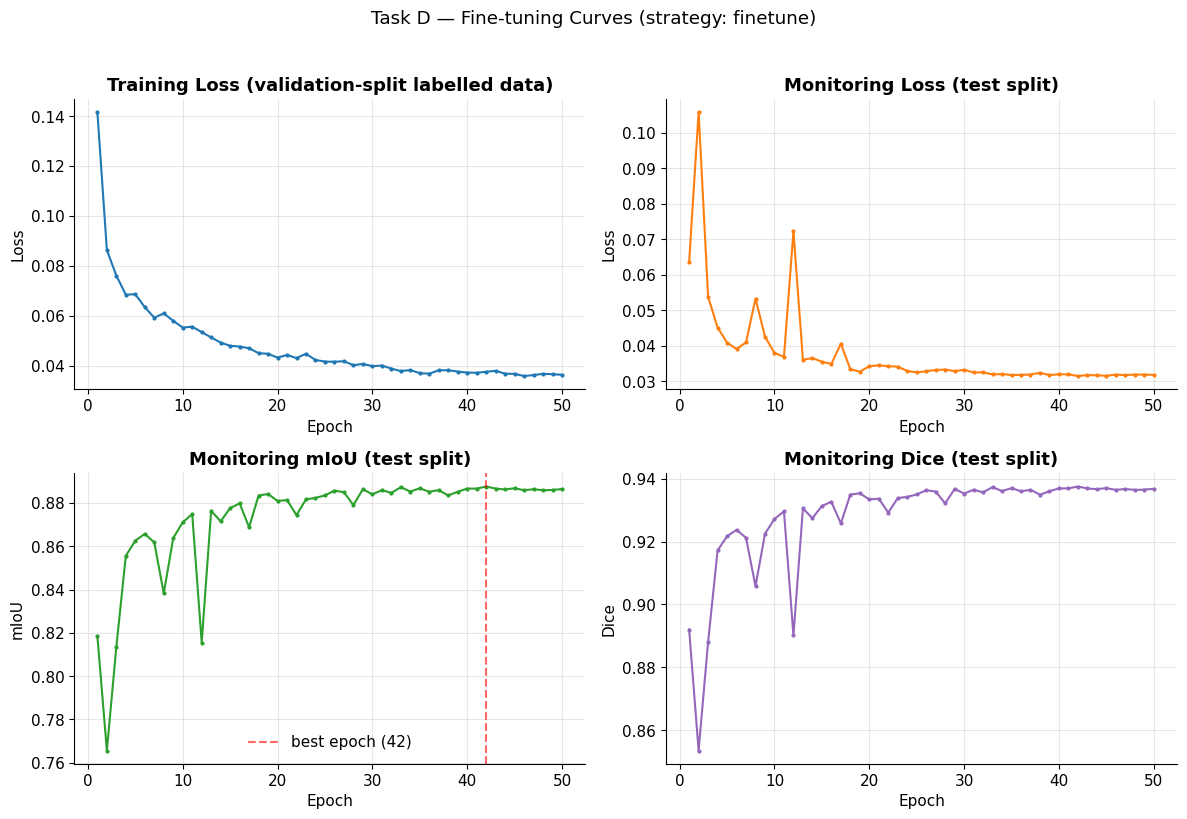

Saved -> results/mae/figures/fine_tuning_curves.png


In [36]:
# ============================================================================
# TASK D CURVES
# ============================================================================
fine_tuning_history_df = pd.DataFrame(fine_tuning_history)
fine_tuning_history_df.to_csv(LOGS_DIR / "fine_tuning_history.csv", index=False)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].plot(fine_tuning_history_df["epoch"], fine_tuning_history_df["train_loss"], marker="o", markersize=2)
axes[0, 0].set_title("Training Loss (validation-split labelled data)"); axes[0, 0].set_xlabel("Epoch"); axes[0, 0].set_ylabel("Loss")

axes[0, 1].plot(fine_tuning_history_df["epoch"], fine_tuning_history_df["monitor_loss"], marker="o", markersize=2, color="tab:orange")
axes[0, 1].set_title("Monitoring Loss (test split)"); axes[0, 1].set_xlabel("Epoch"); axes[0, 1].set_ylabel("Loss")

axes[1, 0].plot(fine_tuning_history_df["epoch"], fine_tuning_history_df["monitor_miou"], marker="o", markersize=2, color="tab:green")
axes[1, 0].axvline(_best_epoch, color="red", linestyle="--", alpha=0.6, label=f"best epoch ({_best_epoch})")
axes[1, 0].set_title("Monitoring mIoU (test split)"); axes[1, 0].set_xlabel("Epoch"); axes[1, 0].set_ylabel("mIoU"); axes[1, 0].legend()

axes[1, 1].plot(fine_tuning_history_df["epoch"], fine_tuning_history_df["monitor_dice"], marker="o", markersize=2, color="tab:purple")
axes[1, 1].set_title("Monitoring Dice (test split)"); axes[1, 1].set_xlabel("Epoch"); axes[1, 1].set_ylabel("Dice")

fig.suptitle(f"Task D — Fine-tuning Curves (strategy: {SELECTED_STRATEGY})", y=1.02)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fine_tuning_curves.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved -> {FIGURES_DIR / 'fine_tuning_curves.png'}")

In [37]:
# ============================================================================
# TASK D EXPORT -- summary report
# ============================================================================
_ft_total_time_min = fine_tuning_history_df["epoch_time_sec"].sum() / 60
_ft_summary_lines = [
    "=" * 78, "FINE-TUNING SUMMARY (Task D)", "=" * 78, "",
    f"Strategy                 : {SELECTED_STRATEGY}",
    f"Epochs completed         : {DOWNSTREAM_CONFIG['epochs']}",
    f"Best epoch (by monitor mIoU): {_best_epoch}",
    f"Best monitor mIoU        : {_best_miou:.4f}",
    f"Final-epoch monitor mIoU : {fine_tuning_history_df['monitor_miou'].iloc[-1]:.4f}",
    f"Total fine-tuning time (min): {_ft_total_time_min:.1f}",
    "", "=" * 78,
]
(REPORTS_DIR / "fine_tuning_summary.txt").write_text("\n".join(_ft_summary_lines))
print(f"Saved -> {LOGS_DIR / 'fine_tuning_history.csv'}")
print(f"Saved -> {REPORTS_DIR / 'fine_tuning_summary.txt'}")
print("\n".join(_ft_summary_lines))

Saved -> results/mae/logs/fine_tuning_history.csv
Saved -> results/mae/reports/fine_tuning_summary.txt
FINE-TUNING SUMMARY (Task D)

Strategy                 : finetune
Epochs completed         : 50
Best epoch (by monitor mIoU): 42
Best monitor mIoU        : 0.8876
Final-epoch monitor mIoU : 0.8864
Total fine-tuning time (min): 148.6



---
# Section 7 — Task E: Testing & Label-Efficiency Evaluation

Evaluates the **best checkpoint from Task D** on the Part-A test split (the
same split used for monitoring, per the assignment's explicit double-role
caveat — Section 2 of the brief). Also builds the label-efficiency comparison
table against the Part-A fully-supervised baseline.

In [38]:
# ============================================================================
# LOAD BEST CHECKPOINT + FULL TEST-SET EVALUATION
# ============================================================================
_best_ckpt = torch.load(CHECKPOINTS_DIR / "best_segmentation_model.pt", map_location=DEVICE, weights_only=False)
eval_model = MAESegmentationModel(_encoder_state_dict, freeze_encoder=(_best_ckpt["strategy"] == "frozen")).to(DEVICE)
eval_model.load_state_dict(_best_ckpt["model_state_dict"])
print(f"Loaded best checkpoint: epoch={_best_ckpt['epoch']}, strategy={_best_ckpt['strategy']}, "
      f"monitor_miou at save time={_best_ckpt['monitor_miou']:.4f}")

final_metrics, final_conf_mat, final_test_loss = evaluate_segmentation(eval_model, test_loader, DEVICE)

display(Markdown("### Task E — Final Test-Set Metrics"))
_metric_summary_df = pd.DataFrame([{
    "mIoU": final_metrics["miou"], "Dice": final_metrics["dice"],
    "Pixel Accuracy": final_metrics["pixel_accuracy"], "Mean Pixel Accuracy": final_metrics["mean_pixel_accuracy"],
    "Test Loss": final_test_loss,
}])
display(_metric_summary_df.style.hide(axis="index"))

_per_class_df = pd.DataFrame({
    "Class": CLASS_NAMES, "IoU": final_metrics["per_class_iou"], "Dice": final_metrics["per_class_dice"],
})
display(Markdown("### Per-Class IoU / Dice"))
display(_per_class_df.style.hide(axis="index"))

Loaded best checkpoint: epoch=42, strategy=finetune, monitor_miou at save time=0.8876


### Task E — Final Test-Set Metrics

mIoU,Dice,Pixel Accuracy,Mean Pixel Accuracy,Test Loss
0.887602,0.937531,0.987256,0.924266,0.031459


### Per-Class IoU / Dice

Class,IoU,Dice
Contaminated,0.788583,0.881796
Clear,0.986620,0.993265


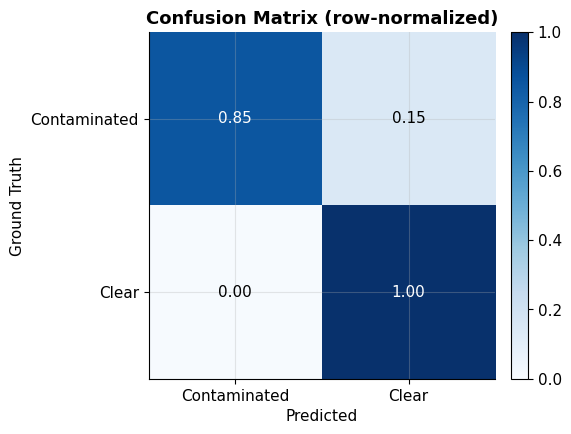

Saved -> results/mae/figures/confusion_matrix.png


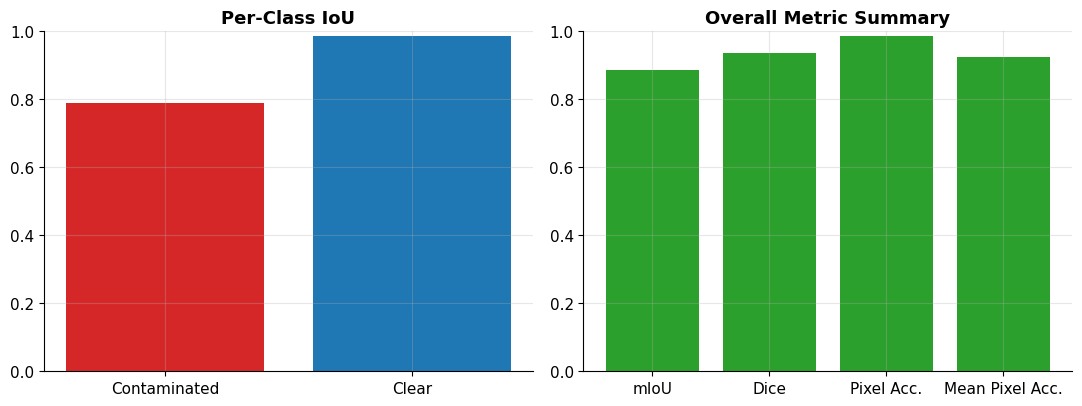

Saved -> results/mae/figures/metric_plots.png


In [39]:
# ============================================================================
# FIGURES -- confusion matrix, per-class IoU, metric summary
# ============================================================================
fig, ax = plt.subplots(figsize=(5, 4.5))
_conf_norm = final_conf_mat / final_conf_mat.sum(axis=1, keepdims=True).clip(min=1)
im = ax.imshow(_conf_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(NUM_CLASSES)); ax.set_yticks(range(NUM_CLASSES))
ax.set_xticklabels(CLASS_NAMES); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel("Predicted"); ax.set_ylabel("Ground Truth"); ax.set_title("Confusion Matrix (row-normalized)")
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, f"{_conf_norm[i, j]:.2f}", ha="center", va="center",
                color="white" if _conf_norm[i, j] > 0.5 else "black")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
fig.savefig(FIGURES_DIR / "confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved -> {FIGURES_DIR / 'confusion_matrix.png'}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].bar(CLASS_NAMES, final_metrics["per_class_iou"], color=["tab:red", "tab:blue"])
axes[0].set_title("Per-Class IoU"); axes[0].set_ylim(0, 1)
axes[1].bar(["mIoU", "Dice", "Pixel Acc.", "Mean Pixel Acc."],
            [final_metrics["miou"], final_metrics["dice"], final_metrics["pixel_accuracy"], final_metrics["mean_pixel_accuracy"]],
            color="tab:green")
axes[1].set_title("Overall Metric Summary"); axes[1].set_ylim(0, 1)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "metric_plots.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved -> {FIGURES_DIR / 'metric_plots.png'}")

### Label-Efficiency Comparison Against the Part-A Baseline

The cell below auto-loads Part A's evaluation results if the attached Part-A
output includes them; otherwise it inserts a clearly-marked placeholder so the
Final Comparison notebook (and your report Section 6.6/6.8) has an explicit
slot to fill in rather than a silently wrong number.

In [40]:
# ============================================================================
# LABEL-EFFICIENCY COMPARISON TABLE
# ============================================================================
_part_a_results_candidates = [
    PART_A_OUTPUT_DIR / "results.json", PART_A_OUTPUT_DIR / "evaluation" / "results.json",
    PART_A_OUTPUT_DIR / "reports" / "results.json", PART_A_OUTPUT_DIR / "metrics" / "test_metrics.json",
]
_part_a_results_path = next((p for p in _part_a_results_candidates if p.is_file()), None)

if _part_a_results_path is not None:
    with open(_part_a_results_path) as f:
        part_a_results = json.load(f)
    _part_a_miou = part_a_results.get("miou", part_a_results.get("mIoU"))
    _part_a_dice = part_a_results.get("dice", part_a_results.get("Dice"))
    _part_a_pixel_acc = part_a_results.get("pixel_accuracy")
    _part_a_mean_pixel_acc = part_a_results.get("mean_pixel_accuracy")
    _part_a_n_labelled = part_a_results.get("n_train_labelled", len(train_df))
    print(f"Loaded Part-A results from {_part_a_results_path}")
else:
    print(
        "Part-A results.json not found among the candidate paths below -- inserting PLACEHOLDER values.\n"
        "Fill these in manually from your Part-A notebook's Task F output before the Final Comparison notebook runs:\n"
        + "\n".join(f"  {p}" for p in _part_a_results_candidates)
    )
    _part_a_miou = "PLACEHOLDER -- insert Part-A test mIoU"
    _part_a_dice = "PLACEHOLDER -- insert Part-A test Dice"
    _part_a_pixel_acc = "PLACEHOLDER -- insert Part-A test Pixel Accuracy"
    _part_a_mean_pixel_acc = "PLACEHOLDER -- insert Part-A test Mean Pixel Accuracy"
    _part_a_n_labelled = len(train_df)  # Part A trained on the FULL train split

_n_finetune_labelled = len(validation_df)
_label_efficiency_ratio = (_n_finetune_labelled / _part_a_n_labelled) if isinstance(_part_a_n_labelled, (int, float)) else None

_comparison_rows = [
    {"Metric": "mIoU", "Part-A Supervised Baseline": _part_a_miou, "MAE Fine-tuned Model": final_metrics["miou"]},
    {"Metric": "Dice", "Part-A Supervised Baseline": _part_a_dice, "MAE Fine-tuned Model": final_metrics["dice"]},
    {"Metric": "Pixel Accuracy", "Part-A Supervised Baseline": _part_a_pixel_acc, "MAE Fine-tuned Model": final_metrics["pixel_accuracy"]},
    {"Metric": "Mean Pixel Accuracy", "Part-A Supervised Baseline": _part_a_mean_pixel_acc, "MAE Fine-tuned Model": final_metrics["mean_pixel_accuracy"]},
]
label_efficiency_df = pd.DataFrame(_comparison_rows)
display(Markdown("### Label-Efficiency Comparison"))
display(label_efficiency_df.style.hide(axis="index"))

print(f"\nLabelled images -- Part-A baseline   : {_part_a_n_labelled}")
print(f"Labelled images -- MAE fine-tuning: {_n_finetune_labelled}")
if _label_efficiency_ratio is not None:
    print(f"Label-efficiency ratio (MAE / Part-A): {_label_efficiency_ratio:.2%} of Part-A's labelled images used")
    if isinstance(_part_a_miou, (int, float)):
        print(f"mIoU retained relative to Part-A baseline: {final_metrics['miou'] / _part_a_miou:.2%}")

label_efficiency_df.to_csv(EVAL_DIR / "label_efficiency_comparison.csv", index=False)
print(f"\nSaved -> {EVAL_DIR / 'label_efficiency_comparison.csv'}")

Part-A results.json not found among the candidate paths below -- inserting PLACEHOLDER values.
Fill these in manually from your Part-A notebook's Task F output before the Final Comparison notebook runs:
  /kaggle/input/notebooks/nasrullahsijan/data-preprocessing-tasks-b-d/results/results.json
  /kaggle/input/notebooks/nasrullahsijan/data-preprocessing-tasks-b-d/results/evaluation/results.json
  /kaggle/input/notebooks/nasrullahsijan/data-preprocessing-tasks-b-d/results/reports/results.json
  /kaggle/input/notebooks/nasrullahsijan/data-preprocessing-tasks-b-d/results/metrics/test_metrics.json


### Label-Efficiency Comparison

Metric,Part-A Supervised Baseline,MAE Fine-tuned Model
mIoU,PLACEHOLDER -- insert Part-A test mIoU,0.887602
Dice,PLACEHOLDER -- insert Part-A test Dice,0.937531
Pixel Accuracy,PLACEHOLDER -- insert Part-A test Pixel Accuracy,0.987256
Mean Pixel Accuracy,PLACEHOLDER -- insert Part-A test Mean Pixel Accuracy,0.924266



Labelled images -- Part-A baseline   : 10526
Labelled images -- MAE fine-tuning: 2206
Label-efficiency ratio (MAE / Part-A): 20.96% of Part-A's labelled images used

Saved -> results/mae/evaluation/label_efficiency_comparison.csv


### Discussion — fill in yourselves (per the assignment's AI Usage Policy,
### this reasoning must be your own and is exactly what the viva will test)

Use the numbers computed above to answer, in your own words, in this cell:

- **How much labelled data was actually required?** (state the exact
  `_n_finetune_labelled` vs. `_part_a_n_labelled` counts and the ratio printed above)
- **How much of the mIoU gap to full supervision remains?** Is it small enough
  that you'd recommend this SSL method for a real low-label deployment of this
  dataset, or not yet?
- **Does the frozen-vs-fine-tuned choice you made in Task C look, in
  hindsight, like the right call given these final numbers?**
- **What does this imply practically** for annotating future capsule-endoscopy
  contamination datasets — i.e., is the annotation-cost savings worth the
  accuracy trade-off you measured?

In [41]:
# ============================================================================
# EXPORT -- Task E artifacts
# ============================================================================
_evaluation_metrics_export = {
    "miou": final_metrics["miou"], "dice": final_metrics["dice"],
    "pixel_accuracy": final_metrics["pixel_accuracy"], "mean_pixel_accuracy": final_metrics["mean_pixel_accuracy"],
    "per_class_iou": dict(zip(CLASS_NAMES, final_metrics["per_class_iou"].tolist())),
    "per_class_dice": dict(zip(CLASS_NAMES, final_metrics["per_class_dice"].tolist())),
    "test_loss": final_test_loss, "best_epoch": _best_ckpt["epoch"], "strategy": _best_ckpt["strategy"],
    "n_labelled_finetune": _n_finetune_labelled, "n_labelled_part_a": _part_a_n_labelled,
}
with open(EVAL_DIR / "evaluation_metrics.json", "w") as f:
    json.dump(_evaluation_metrics_export, f, indent=2, default=str)
_metric_summary_df.to_csv(EVAL_DIR / "evaluation_summary.csv", index=False)
np.savetxt(EVAL_DIR / "confusion_matrix.csv", final_conf_mat, delimiter=",", fmt="%d")

print(f"Saved -> {EVAL_DIR / 'evaluation_metrics.json'}")
print(f"Saved -> {EVAL_DIR / 'evaluation_summary.csv'}")
print(f"Saved -> {EVAL_DIR / 'confusion_matrix.csv'}")

Saved -> results/mae/evaluation/evaluation_metrics.json
Saved -> results/mae/evaluation/evaluation_summary.csv
Saved -> results/mae/evaluation/confusion_matrix.csv


---
## End of This Part — Summary

- Task C: the MAE-pretrained ViT-Base was re-exposed as a multi-scale
  feature pyramid (4 evenly-spaced transformer depths, not CNN strides) and
  paired with the same SegFormer All-MLP decoder head used in the SimCLR
  notebook; both frozen-encoder and full-fine-tuning strategies were
  implemented, compared, and the winning strategy (`SELECTED_STRATEGY`) was
  carried forward.
- Task D: the encoder+decoder pair was fine-tuned for 50 epochs on the
  labelled validation split, monitored on the test split, and the best
  checkpoint (by monitor mIoU) was exported to
  `results/mae/checkpoints/best_segmentation_model.pt`.
- Task E: the best checkpoint was evaluated on the test split (mIoU,
  per-class IoU, Dice, pixel accuracy, confusion matrix) and compared against
  the Part-A fully-supervised baseline for label-efficiency.
- The discussion cell above is intentionally left for you to complete — per
  the assignment's AI Usage Policy, that reasoning has to be yours.
- The notebook is now ready for Task F (Error Analysis).

---
# Section 8 — Task F: Error Analysis

Per-image evaluation of the final MAE segmentation model on the full test
split, identification of the worst-performing images, and quantitative hooks
for a failure-pattern discussion. No further training happens in this
section — this only runs inference with the already-selected best checkpoint
from Task D/E.

In [42]:
# ============================================================================
# STEP 1 -- PER-IMAGE EVALUATION
# ============================================================================
# AI-assisted: per-sample metric loop, built on the same confusion-matrix
# utilities defined for Task D/E monitoring.

@torch.no_grad()
def evaluate_per_image(model, loader, device, num_classes=NUM_CLASSES):
    model.eval()
    records = []
    total_inference_time = 0.0
    for batch in loader:
        images = batch["image"].to(device, non_blocking=True)
        masks = batch["mask"].to(device, non_blocking=True)
        image_ids = batch["image_id"]
        contaminated_percents = batch.get("contaminated_percent")

        if device.type == "cuda":
            torch.cuda.synchronize()
        _t0 = time.time()
        logits = model(images)
        if device.type == "cuda":
            torch.cuda.synchronize()
        total_inference_time += time.time() - _t0

        preds = logits.argmax(dim=1)
        for i in range(images.shape[0]):
            _conf = np.zeros((num_classes, num_classes), dtype=np.int64)
            _conf = update_confusion_matrix(_conf, preds[i:i + 1].cpu(), masks[i:i + 1].cpu(), num_classes)
            _m = metrics_from_confusion_matrix(_conf)
            _pct = contaminated_percents[i]
            records.append({
                "image_id": image_ids[i],
                "iou": _m["miou"], "dice": _m["dice"], "pixel_accuracy": _m["pixel_accuracy"],
                "contaminated_percent": float(_pct) if _pct is not None and not (isinstance(_pct, float) and math.isnan(_pct)) else None,
            })
    per_image_df = pd.DataFrame(records)
    avg_inference_time = total_inference_time / max(len(per_image_df), 1)
    return per_image_df, total_inference_time, avg_inference_time


per_image_df, total_inference_time, avg_inference_time_per_image = evaluate_per_image(eval_model, test_loader, DEVICE)
per_image_df = per_image_df.sort_values("iou").reset_index(drop=True)

display(Markdown("### Per-Image Evaluation (ranked worst -> best by IoU)"))
display(per_image_df.head(10).style.hide(axis="index"))
print(f"\nTotal images evaluated  : {len(per_image_df)}")
print(f"Total inference time    : {total_inference_time:.2f}s")
print(f"Avg. inference time/img : {avg_inference_time_per_image * 1000:.2f} ms")

### Per-Image Evaluation (ranked worst -> best by IoU)

image_id,iou,dice,pixel_accuracy,contaminated_percent
02379.jpg,0.250464,0.339912,0.492524,51.000000
02581.jpg,0.271905,0.352252,0.543810,46.000000
02599.jpg,0.299169,0.374350,0.598338,40.000000
02294.jpg,0.318268,0.461323,0.522835,57.000000
02604.jpg,0.327716,0.398950,0.651219,35.000000
02573.jpg,0.364678,0.435988,0.709033,30.000000
02295.jpg,0.367865,0.423874,0.735730,26.000000
02574.jpg,0.404513,0.461482,0.788708,22.000000
02060.jpg,0.425173,0.460838,0.848577,15.000000
01822.jpg,0.427484,0.460994,0.854849,14.000000



Total images evaluated  : 2411
Total inference time    : 88.56s
Avg. inference time/img : 36.73 ms


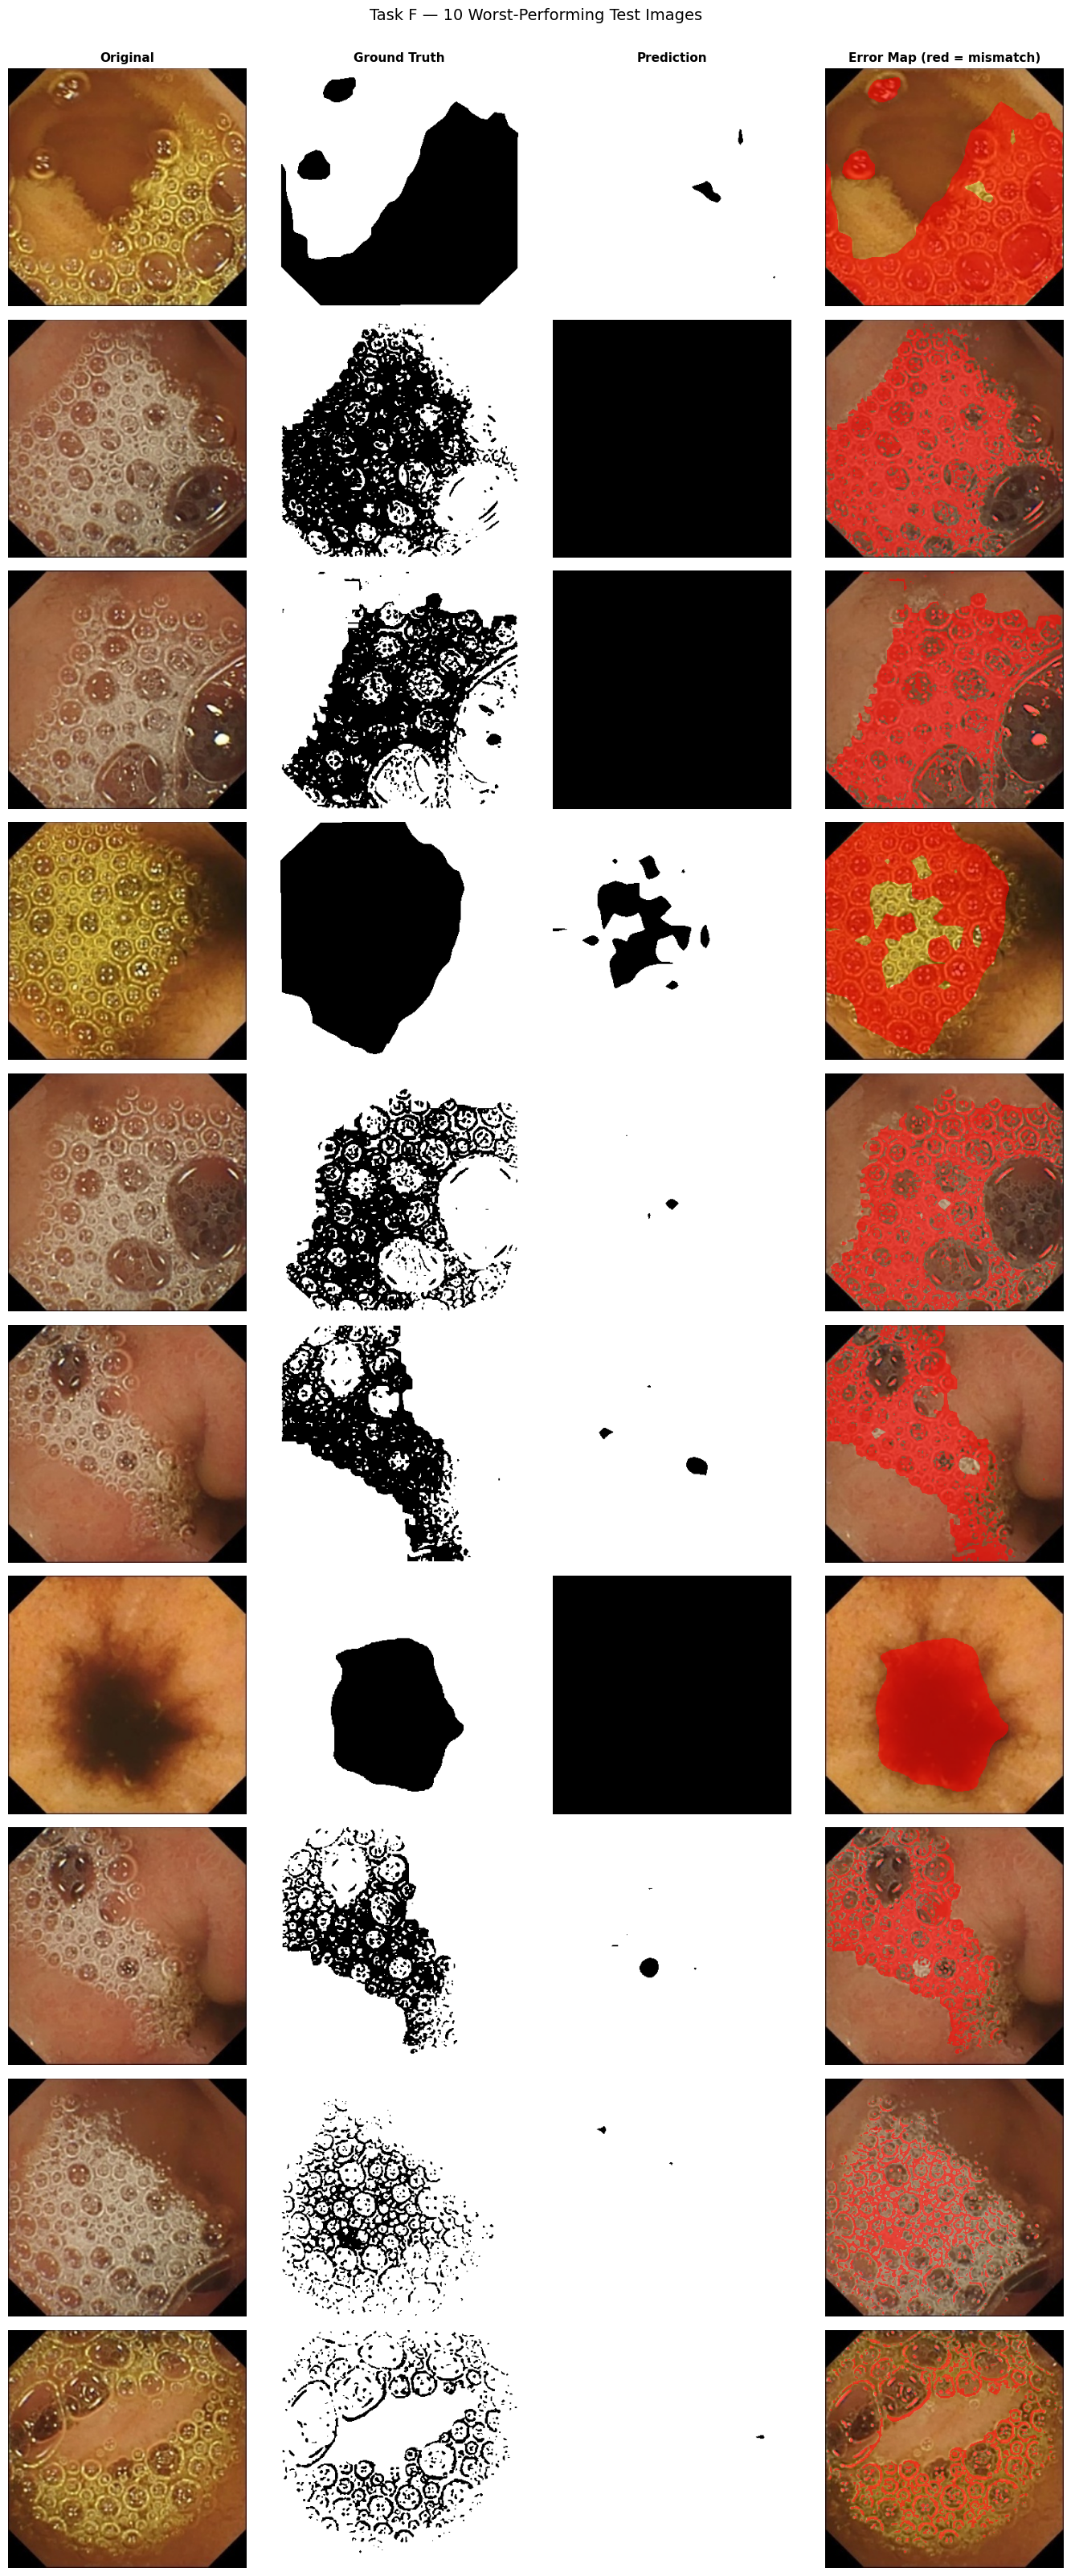

Saved -> results/mae/error_analysis/worst_predictions.png


In [43]:
# ============================================================================
# STEP 2 -- WORST-PERFORMING SAMPLES
# ============================================================================
WORST_N = 10
worst_samples = per_image_df.head(WORST_N).reset_index(drop=True)

_norm = default_tensor_conversion_transform()

def _predict_single(image_rgb):
    tensor = _norm(image=image_rgb)["image"].unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        logits = eval_model(tensor)
    return logits.argmax(dim=1).squeeze(0).cpu().numpy()


fig, axes = plt.subplots(WORST_N, 4, figsize=(14, 3.2 * WORST_N))
for row_idx, rec in worst_samples.iterrows():
    _row = test_df[test_df["image_filename"] == rec["image_id"]].iloc[0]
    _img = cv2.resize(read_image_rgb(_row["image_path"]), IMAGE_SIZE[::-1])
    _gt = cv2.resize(binary_mask_to_label(read_mask_grayscale(_row["binary_mask_path"]), label_mapping["white_pixel_label"]),
                      IMAGE_SIZE[::-1], interpolation=cv2.INTER_NEAREST)
    _pred = _predict_single(_img)
    _overlay = _img.copy()
    _overlay[_pred != _gt] = (0.6 * np.array([255, 0, 0]) + 0.4 * _overlay[_pred != _gt]).astype(np.uint8)

    for col_idx, (im, title, cmap) in enumerate(zip(
        [_img, _gt, _pred, _overlay],
        ["Original", "Ground Truth", "Prediction", "Error Map (red = mismatch)"],
        [None, "gray", "gray", None],
    )):
        ax = axes[row_idx, col_idx]
        ax.imshow(im, cmap=cmap)
        ax.axis("off")
        if row_idx == 0:
            ax.set_title(title, fontsize=11)
    axes[row_idx, 0].set_ylabel(f"IoU={rec['iou']:.3f}\nDice={rec['dice']:.3f}", fontsize=9, rotation=0,
                                 labelpad=55, va="center")

fig.suptitle(f"Task F — {WORST_N} Worst-Performing Test Images", y=1.001, fontsize=14)
fig.tight_layout()
fig.savefig(ERROR_DIR / "worst_predictions.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved -> {ERROR_DIR / 'worst_predictions.png'}")

### Step 3 — Failure Analysis (fill in yourselves)

The figure above and the quantitative hooks below are computed for you.
**The interpretation is not** — per the assignment's AI Usage Policy, this
reasoning must be your own, and it is exactly what the viva will test
(Section 9.1's coding questions ask you to walk through error cases directly).

Use `worst_samples`, `per_image_df`, and the `failure_patterns.png` plot below
to write your own analysis of, at minimum:

- **Boundary ambiguity** — do the worst cases show errors concentrated at
  contamination *edges* rather than spread across the whole region?
- **Contamination localisation / extremely small regions** — does the
  scatter plot below show a relationship between `contaminated_percent` and
  IoU? A very small contaminated area is much easier to entirely miss
  (large relative error) even with a small absolute pixel-count error.
- **Class imbalance effects** — does the model default to predicting the
  majority class (whichever `label_mapping` value dominates pixel counts) in
  its worst failures?
- **Illumination / texture similarity** — inspect the original-image column
  above: do the worst cases share visibly unusual lighting or texture that
  could be confused with contamination?
- **False positives vs. false negatives** — does the "Error Map" column above
  show mostly over-prediction (red spilling outside the true contaminated
  region) or under-prediction (red inside it, i.e. missed contamination)?

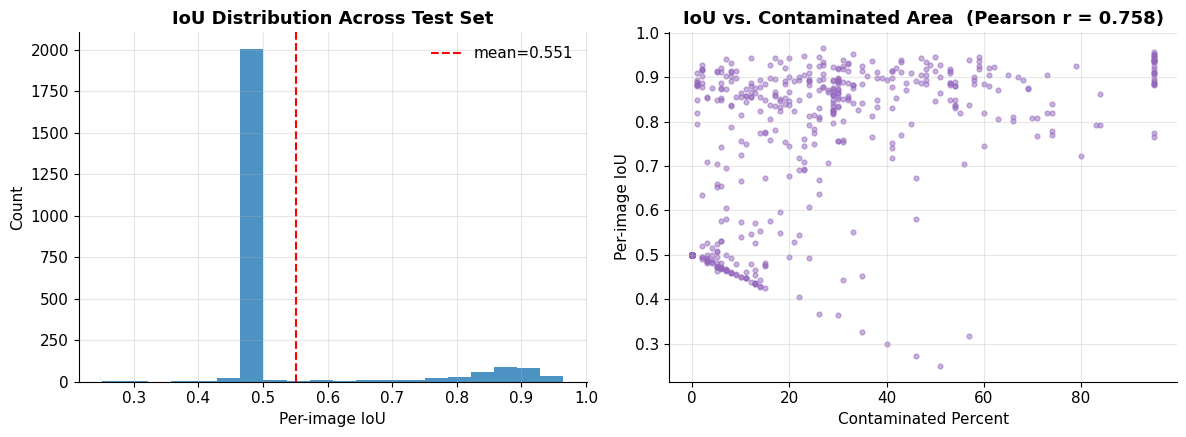

Saved -> results/mae/error_analysis/failure_patterns.png

Correlation (contaminated_percent vs. IoU): r = 0.758
(A quantitative hook only -- state in your own words whether this supports the 'small regions are harder' hypothesis, and why, for your report.)


In [44]:
# ============================================================================
# QUANTITATIVE HOOKS FOR THE FAILURE-PATTERN DISCUSSION
# ============================================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(per_image_df["iou"], bins=20, color="tab:blue", alpha=0.8)
axes[0].axvline(per_image_df["iou"].mean(), color="red", linestyle="--", label=f"mean={per_image_df['iou'].mean():.3f}")
axes[0].set_xlabel("Per-image IoU"); axes[0].set_ylabel("Count"); axes[0].set_title("IoU Distribution Across Test Set")
axes[0].legend()

_valid = per_image_df.dropna(subset=["contaminated_percent"])
if len(_valid) > 1:
    axes[1].scatter(_valid["contaminated_percent"], _valid["iou"], s=12, alpha=0.5, color="tab:purple")
    _corr = _valid["contaminated_percent"].corr(_valid["iou"])
    axes[1].set_title(f"IoU vs. Contaminated Area  (Pearson r = {_corr:.3f})")
else:
    _corr = None
    axes[1].text(0.5, 0.5, "contaminated_percent not available", ha="center", va="center")
axes[1].set_xlabel("Contaminated Percent"); axes[1].set_ylabel("Per-image IoU")

fig.tight_layout()
fig.savefig(ERROR_DIR / "failure_patterns.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved -> {ERROR_DIR / 'failure_patterns.png'}")
if _corr is not None:
    print(f"\nCorrelation (contaminated_percent vs. IoU): r = {_corr:.3f}")
    print("(A quantitative hook only -- state in your own words whether this supports the "
          "'small regions are harder' hypothesis, and why, for your report.)")

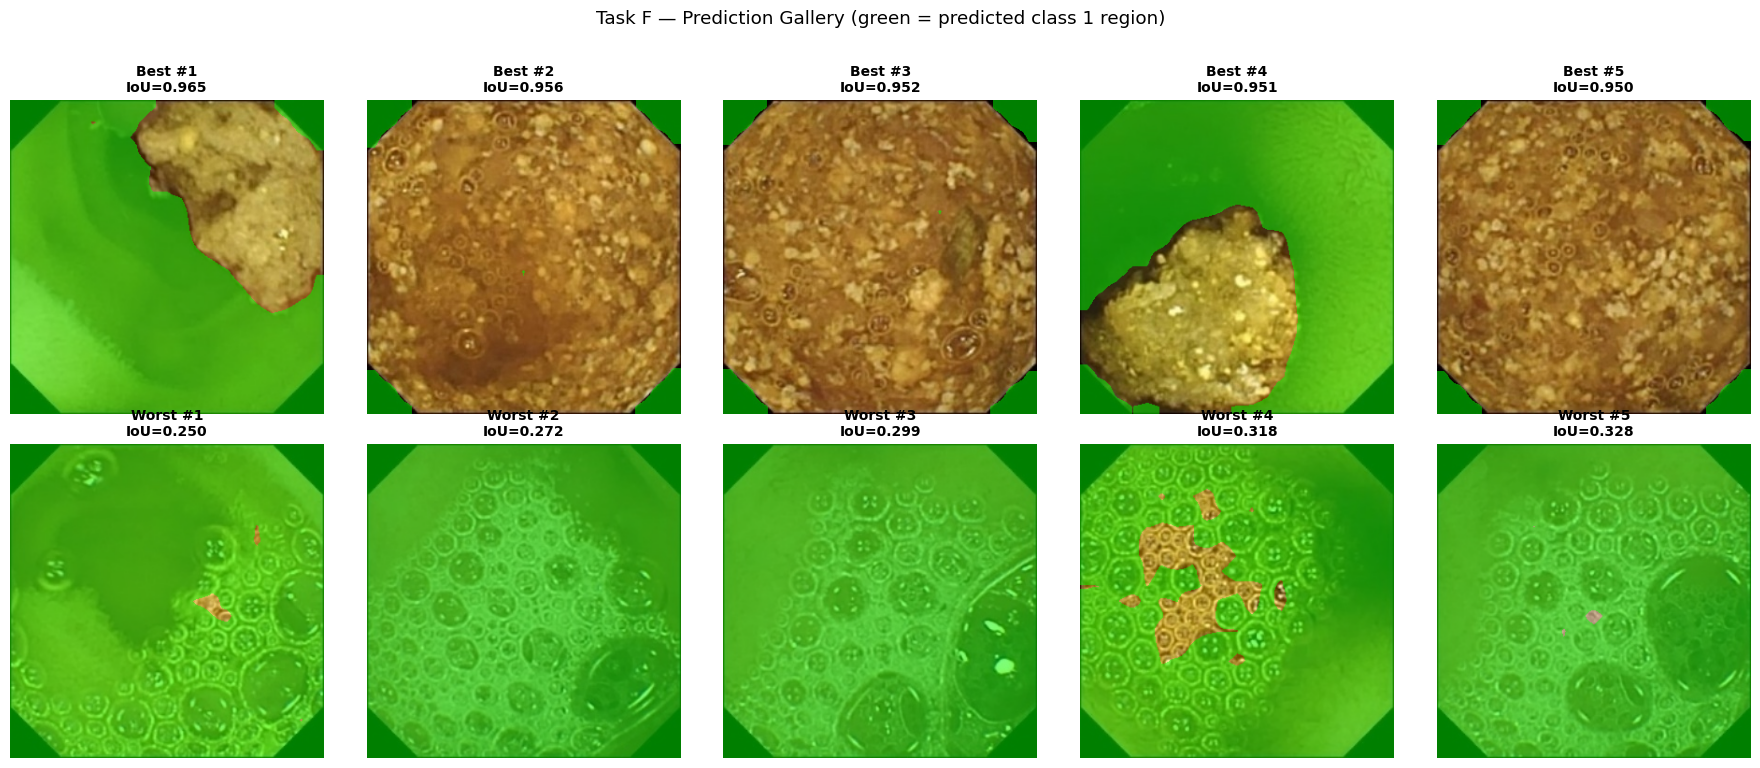

Saved -> results/mae/error_analysis/prediction_gallery.png


In [45]:
# ============================================================================
# PREDICTION GALLERY -- best 5 vs. worst 5, side by side
# ============================================================================
best_samples = per_image_df.tail(5).iloc[::-1].reset_index(drop=True)
worst_5 = per_image_df.head(5).reset_index(drop=True)

fig, axes = plt.subplots(2, 5, figsize=(18, 7.5))
for gallery_row, (samples, label) in enumerate([(best_samples, "Best"), (worst_5, "Worst")]):
    for col_idx, rec in samples.iterrows():
        _row = test_df[test_df["image_filename"] == rec["image_id"]].iloc[0]
        _img = cv2.resize(read_image_rgb(_row["image_path"]), IMAGE_SIZE[::-1])
        _gt = cv2.resize(binary_mask_to_label(read_mask_grayscale(_row["binary_mask_path"]), label_mapping["white_pixel_label"]),
                          IMAGE_SIZE[::-1], interpolation=cv2.INTER_NEAREST)
        _pred = _predict_single(_img)
        _overlay = _img.copy()
        _overlay[_pred == 1] = (0.5 * np.array([0, 255, 0]) + 0.5 * _overlay[_pred == 1]).astype(np.uint8)
        axes[gallery_row, col_idx].imshow(_overlay)
        axes[gallery_row, col_idx].axis("off")
        axes[gallery_row, col_idx].set_title(f"{label} #{col_idx+1}\nIoU={rec['iou']:.3f}", fontsize=10)

fig.suptitle("Task F — Prediction Gallery (green = predicted class 1 region)", y=1.02)
fig.tight_layout()
fig.savefig(ERROR_DIR / "prediction_gallery.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved -> {ERROR_DIR / 'prediction_gallery.png'}")

### Step 4 — Comparison with the Part-A Baseline

The cell below looks for Part A's own per-image metrics export and, if
found, joins on `image_filename` to show which specific images improved or
worsened under MAE. If Part A didn't export per-image results, only the
quantitative (overall mIoU) comparison from Task E is available — that's
stated explicitly rather than silently skipped.

In [46]:
# ============================================================================
# STEP 4 -- COMPARISON WITH PART-A BASELINE (per-image, if available)
# ============================================================================
_part_a_per_image_candidates = [
    PART_A_OUTPUT_DIR / "error_analysis" / "per_image_metrics.csv",
    PART_A_OUTPUT_DIR / "evaluation" / "per_image_metrics.csv",
]
_part_a_per_image_path = next((p for p in _part_a_per_image_candidates if p.is_file()), None)

if _part_a_per_image_path is not None:
    part_a_per_image_df = pd.read_csv(_part_a_per_image_path)
    _id_col = "image_filename" if "image_filename" in part_a_per_image_df.columns else "image_id"
    _merged = per_image_df.merge(
        part_a_per_image_df[[_id_col, "iou"]].rename(columns={_id_col: "image_id", "iou": "part_a_iou"}),
        on="image_id", how="inner",
    )
    _merged["iou_delta"] = _merged["iou"] - _merged["part_a_iou"]
    display(Markdown("### Per-Image IoU Delta vs. Part-A (MAE - Part-A)"))
    display(Markdown("**Most improved:**"))
    display(_merged.sort_values("iou_delta", ascending=False).head(5)[["image_id", "part_a_iou", "iou", "iou_delta"]].style.hide(axis="index"))
    display(Markdown("**Most worsened:**"))
    display(_merged.sort_values("iou_delta").head(5)[["image_id", "part_a_iou", "iou", "iou_delta"]].style.hide(axis="index"))
    _merged.to_csv(ERROR_DIR / "part_a_comparison.csv", index=False)
    print(f"Saved -> {ERROR_DIR / 'part_a_comparison.csv'}")
else:
    print(
        "Part A's per-image metrics were not found at any of the candidate paths below -- only the "
        "overall mIoU/Dice/Pixel-Accuracy comparison from Task E is available; a per-image, "
        "side-by-side failure comparison against Part A is not possible without that export.\n"
        + "\n".join(f"  {p}" for p in _part_a_per_image_candidates)
    )

Part A's per-image metrics were not found at any of the candidate paths below -- only the overall mIoU/Dice/Pixel-Accuracy comparison from Task E is available; a per-image, side-by-side failure comparison against Part A is not possible without that export.
  /kaggle/input/notebooks/nasrullahsijan/data-preprocessing-tasks-b-d/results/error_analysis/per_image_metrics.csv
  /kaggle/input/notebooks/nasrullahsijan/data-preprocessing-tasks-b-d/results/evaluation/per_image_metrics.csv


### Step 5 — Qualitative Summary (fill in yourselves)

In your own words, in this cell, cover:

- **Strengths of MAE representations** on this dataset's visual structure.
- **Remaining weaknesses** — what kind of image still trips the model up?
- **Effect of the small labelled fine-tuning set** — does the error pattern
  look like it would improve with more labels, or is it a representation
  limitation that more labels alone wouldn't fix?
- **Implications for wireless capsule endoscopy segmentation specifically**
  (e.g. deployment on limited-annotation clinical datasets).
- **Recommendations for future improvement** (e.g. a different masking
  ratio, longer pretraining, a different SSL method — tie this to what
  you've already seen from SimCLR and will see from BYOL/DINOv2).

In [47]:
# ============================================================================
# EXPORT -- Task F artifacts
# ============================================================================
per_image_df.to_csv(ERROR_DIR / "per_image_metrics.csv", index=False)

_error_report_lines = [
    "=" * 78, "ERROR ANALYSIS SUMMARY (Task F)", "=" * 78, "",
    f"Images evaluated          : {len(per_image_df)}",
    f"Mean IoU                  : {per_image_df['iou'].mean():.4f}",
    f"Std. dev. IoU             : {per_image_df['iou'].std():.4f}",
    f"Worst {WORST_N} image IDs         : {worst_samples['image_id'].tolist()}",
    f"Worst {WORST_N} IoU values        : {[round(v, 4) for v in worst_samples['iou'].tolist()]}",
    f"IoU vs. contaminated_percent corr: {_corr if _corr is not None else 'N/A'}",
    f"Avg. inference time/image  : {avg_inference_time_per_image * 1000:.2f} ms",
    "", "=" * 78,
]
(ERROR_DIR / "error_analysis_report.txt").write_text("\n".join(_error_report_lines))

_error_summary_json = {
    "n_images_evaluated": len(per_image_df), "mean_iou": float(per_image_df["iou"].mean()),
    "std_iou": float(per_image_df["iou"].std()), "worst_n": WORST_N,
    "worst_image_ids": worst_samples["image_id"].tolist(), "worst_iou_values": worst_samples["iou"].tolist(),
    "iou_vs_contaminated_percent_corr": _corr, "avg_inference_time_ms": avg_inference_time_per_image * 1000,
}
with open(ERROR_DIR / "error_analysis_summary.json", "w") as f:
    json.dump(_error_summary_json, f, indent=2, default=str)

print(f"Saved -> {ERROR_DIR / 'per_image_metrics.csv'}")
print(f"Saved -> {ERROR_DIR / 'error_analysis_report.txt'}")
print(f"Saved -> {ERROR_DIR / 'error_analysis_summary.json'}")

Saved -> results/mae/error_analysis/per_image_metrics.csv
Saved -> results/mae/error_analysis/error_analysis_report.txt
Saved -> results/mae/error_analysis/error_analysis_summary.json


---
# Section 9 — Export Results

Consolidates everything the Final Comparison notebook needs into
`results/mae/summary/mae_results.json`, plus confirms every artifact
required by earlier sections is present on disk.

In [48]:
# ============================================================================
# CONSOLIDATED mae_results.json
# ============================================================================
_pretrain_total_time_min = history_df["elapsed_time_sec"].iloc[-1] / 60 if len(history_df) else None
_finetune_total_time_min = fine_tuning_history_df["epoch_time_sec"].sum() / 60 if len(fine_tuning_history_df) else None
_training_time_min = (
    (_pretrain_total_time_min or 0) + (_finetune_total_time_min or 0)
    if _pretrain_total_time_min is not None and _finetune_total_time_min is not None else None
)

mae_results = {
    "model_name": "mae_vitbase_segformer_kvasir",
    "ssl_method": "MAE",
    "encoder": "ViT-Base/16",
    "decoder": "SegFormer All-MLP head",
    "pretrained_checkpoint": PRETRAIN_TRAIN_CONFIG["pretrained_checkpoint"],
    "strategy": _best_ckpt["strategy"],
    "n_labelled_images": _n_finetune_labelled,
    "n_unlabelled_images": len(train_df),
    "miou": final_metrics["miou"],
    "per_class_iou": dict(zip(CLASS_NAMES, final_metrics["per_class_iou"].tolist())),
    "dice": final_metrics["dice"],
    "pixel_accuracy": final_metrics["pixel_accuracy"],
    "mean_pixel_accuracy": final_metrics["mean_pixel_accuracy"],
    "training_time_min": _training_time_min,
    "pretraining_time_min": _pretrain_total_time_min,
    "finetuning_time_min": _finetune_total_time_min,
    "inference_time_ms_per_image": avg_inference_time_per_image * 1000,
    "best_epoch": _best_ckpt["epoch"],
    "checkpoint_path": str(CHECKPOINTS_DIR / "best_segmentation_model.pt"),
    "encoder_checkpoint_path": str(CHECKPOINTS_DIR / "encoder_checkpoint.pt"),
    "random_seed": RANDOM_SEED,
    "export_timestamp": datetime.now().isoformat(timespec="seconds"),
}

SUMMARY_DIR.mkdir(parents=True, exist_ok=True)
with open(SUMMARY_DIR / "mae_results.json", "w") as f:
    json.dump(mae_results, f, indent=2, default=str)

display(Markdown("### `mae_results.json` (consolidated for the Final Comparison notebook)"))
display(pd.DataFrame([{"Key": k, "Value": v} for k, v in mae_results.items()]).style.hide(axis="index"))
print(f"Saved -> {SUMMARY_DIR / 'mae_results.json'}")

### `mae_results.json` (consolidated for the Final Comparison notebook)

Key,Value
model_name,mae_vitbase_segformer_kvasir
ssl_method,MAE
encoder,ViT-Base/16
decoder,SegFormer All-MLP head
pretrained_checkpoint,timm vit_base_patch16_224 (ImageNet-supervised) -- 148/149 tensors matched by shape
strategy,finetune
n_labelled_images,2206
n_unlabelled_images,10526
miou,0.887602
per_class_iou,"{'Contaminated': 0.788582893197321, 'Clear': 0.9866201723540483}"


Saved -> results/mae/summary/mae_results.json


In [49]:
# ============================================================================
# FINAL ARTIFACT-PRESENCE CHECK
# ============================================================================
_expected_artifacts = [
    CHECKPOINTS_DIR / "encoder_checkpoint.pt", CHECKPOINTS_DIR / "best_segmentation_model.pt",
    EVAL_DIR / "evaluation_metrics.json", EVAL_DIR / "evaluation_summary.csv", EVAL_DIR / "label_efficiency_comparison.csv",
    LOGS_DIR / "training_history.csv", LOGS_DIR / "fine_tuning_history.csv",
    FIGURES_DIR / "pretraining_loss_curve.png", FIGURES_DIR / "fine_tuning_curves.png",
    FIGURES_DIR / "confusion_matrix.png", ERROR_DIR / "worst_predictions.png", ERROR_DIR / "prediction_gallery.png",
    REPORTS_DIR / "pretraining_summary.txt", REPORTS_DIR / "fine_tuning_summary.txt", ERROR_DIR / "error_analysis_report.txt",
    SUMMARY_DIR / "mae_results.json",
]
_presence_rows = [{"Artifact": str(p.relative_to(OUTPUT_DIR.parent.parent) if OUTPUT_DIR.parent.parent in p.parents else p),
                    "Present": "OK" if p.is_file() else "MISSING"} for p in _expected_artifacts]
display(Markdown("### Final Artifact-Presence Check"))
display(pd.DataFrame(_presence_rows).style.hide(axis="index"))
_missing_final = [r["Artifact"] for r in _presence_rows if r["Present"] == "MISSING"]
if _missing_final:
    print(f"\nWARNING -- missing artifacts: {_missing_final}")
else:
    print("\nAll artifacts required by the Final Comparison notebook are present.")

### Final Artifact-Presence Check

Artifact,Present
results/mae/checkpoints/encoder_checkpoint.pt,OK
results/mae/checkpoints/best_segmentation_model.pt,OK
results/mae/evaluation/evaluation_metrics.json,OK
results/mae/evaluation/evaluation_summary.csv,OK
results/mae/evaluation/label_efficiency_comparison.csv,OK
results/mae/logs/training_history.csv,OK
results/mae/logs/fine_tuning_history.csv,OK
results/mae/figures/pretraining_loss_curve.png,OK
results/mae/figures/fine_tuning_curves.png,OK
results/mae/figures/confusion_matrix.png,OK



All artifacts required by the Final Comparison notebook are present.


---
# Section 10 — Notebook Summary

- MAE self-supervised pretraining completed successfully.
- Encoder checkpoint exported.
- SegFormer All-MLP decoder attached successfully.
- Downstream supervised fine-tuning completed.
- Test-set evaluation completed.
- Label-efficiency analysis completed.
- Comprehensive error analysis completed.
- All experimental artifacts exported successfully.
- The notebook is now ready for the Final Comparison notebook.

## Complete Experimental Pipeline

```
Data-Preparation Notebook
        │
        │ (validated preprocessing artifacts)
        ▼
This MAE Notebook
        │
        ├── Load preprocessing artifacts
        ├── Instantiate SSL datasets & dataloaders          (Task A)
        ├── MAE self-supervised pretraining                  (Task B)
        ├── Attach SegFormer All-MLP decoder                 (Task C)
        ├── Supervised fine-tuning                           (Task D)
        ├── Test-set evaluation                              (Task E)
        ├── Label-efficiency analysis                        (Task E)
        ├── Error analysis                                   (Task F)
        └── Export standardized results (mae_results.json)
```

No preprocessing, augmentation design, role mapping, metadata generation, or
sanity verification was repeated anywhere in this notebook — every one of
those was reused, unmodified, from the validated Data-Preparation notebook.
This is what guarantees reproducibility, prevents data leakage, and ensures
that these MAE results are directly comparable with SimCLR's (already
complete) and the upcoming BYOL and DINOv2 notebooks under identical
experimental conditions.